In [1]:
import numpy as np
import matplotlib.pylab as plt
import pydmd
import scaleogram as scg
from pydmd import DMD
from BopDMD_Regularized import BOPDMD
from MrOptDMD import MrOptDMD
from tqdm.auto import tqdm
plt.rcParams['figure.dpi']=400
np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements

This notebook is dedicated to exploring multiresolution OptDMD.

Multiresolution OptDMD, as I have currently set it up/been using it, works as follows:

1) Fit OptDMD to your dataset $X$ to obtain a reconstruction $X_{Opt}\approx X.$
2) Compute the residual $R^0=X-X_{Opt}.$
3) Partition $R^0$ into two equal time windows $R^0_1$ and $R^0_2$.
4) Fit an OptDMD model to $R^0_1$ and an OptDMD model to $R^0_2$. Concatenate the resulting reconstructions to obtain a reconstruction $R^0_{opt}\approx R^0.$
5) Compute the residual $R^1=X-(X_{opt}+R^0_{opt}).$
6) Repeat steps 3-5 until converged, partitioning $R^n$ into $2^{n+1}$ intervals at each level.

As we progress through levels in the tree, our OptDMD models are fit to progressively smaller time windows. Consequently, the modes found in the first few layers correspond to modes that are essentially always present, while the modes found in deeper layers correspond to potentially transient behaviors.

Note that our final reconstruction of the data, using the above notation, in the case that we have n layers of depth, takes the form

$$X\approx X_{Opt}+\sum_{i=1}^{n-1} R^0.$$

There is a connection between this method and gradient descent on a MSE loss function. Consider flattening out $X$ and $X_{opt}$ into size $nm$ vectors $x$ and $x_{opt}$. The MSE is then $L=\frac{1}{nm}\sum_{i=1}^{nm}(x_i-x_{opt,i})^2.$ We see that

$$\frac{\partial L}{\partial x_{opt,i}}=-\frac{2}{nm}(x_i-x_{opt,i}).$$

Consequently,

$$\nabla L_{x_{opt}} = -\frac{2}{nm}(x-x_{opt}).$$

Reshaping $x$ and $x_{opt}$ into their original $n\times m$ matrix form, this says that

$$\nabla L_{x_{opt}}=-\frac{2}{nm}(X-X_{opt})=-\frac{2}{nm}R^0.$$

Thus, $R^0$ is in the direction of the negative gradient of the MSE loss from our original approximation. Similarly, $R^1$ is in the direction of the negative gradient of the MSE loss from the approximation $X\approx X_{Opt}+R^0_{opt}$, and so on. Thus, by adding the residuals at each step we are doing a form of gradient descent on the MSE loss function (also the RSE loss function that I use below, since the RSE has no additional dependency on our approximation). This class of methods is called gradient boosting. So effectively the method here combines OptDMD, gradient boosting, and multiresolution analysis.

# Fitting MrOptDMD to Widefield Data

In [2]:
SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[:3000,:50].T
SV_norm = np.linalg.norm(SV)
SVn = SV / SV_norm

RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

First we will determine how many levels of depth are necessary to get a good MrOptDMD fit. We will try 3, 4, and 5 levels.

In [3]:
mroptdmd_3 = MrOptDMD(BOPDMD(24),max_level=2,max_cycles=np.inf,min_cycles=-np.inf)
mroptdmd_3.fit(SVn,np.arange(3000))
mroptdmd_4 = MrOptDMD(BOPDMD(24),max_level=3,max_cycles=np.inf,min_cycles=-np.inf)
mroptdmd_4.fit(SVn,np.arange(3000))
mroptdmd_5 = MrOptDMD(BOPDMD(24),max_level=4,max_cycles=np.inf,min_cycles=-np.inf)
mroptdmd_5.fit(SVn,np.arange(3000))

/home/msw1/Notebooks/SBL/AL14_2022-8-15_data/DMD/BopDMD_Regularized.py:258: RuntimeWarning: overflow encountered in exp
  return np.exp(np.outer(t, alpha))
/home/msw1/Notebooks/SBL/AL14_2022-8-15_data/DMD/BopDMD_Regularized.py:513: RuntimeWarning: invalid value encountered in divide
  improvement_ratio = actual_improvement / pred_improvement
/home/msw1/Notebooks/SBL/AL14_2022-8-15_data/DMD/BopDMD_Regularized.py:597: RuntimeWarning: divide by zero encountered in divide
  w = w.dot(np.diag(1 / b))


In [4]:
print("Relative Squared Error with 3 Levels: " + str(RSE(np.real(mroptdmd_3.reconstructed_data),SVn[:,:3000])))
print("Relative Squared Error with 4 Levels: " + str(RSE(np.real(mroptdmd_4.reconstructed_data),SVn[:,:3000])))
print("Relative Squared Error with 5 Levels: " + str(RSE(np.real(mroptdmd_5.reconstructed_data),SVn[:,:3000])))

Relative Squared Error with 3 Levels: 0.04296898883214715
Relative Squared Error with 4 Levels: 0.023346660665041583
Relative Squared Error with 5 Levels: 0.019517798196499063


By adding a fourth level, we halve the reconstruction RSE. However, by adding a fifth layer, we only reduce it by about 25%. Since the complexity of our model grows exponentially with the number of levels, 4 levels seems to be the right number based off this. 

We can also look at the frequency spectra of each reconstruction, and compare it to the spectrum of the original data. We'll look at the frequency spectrum of just the first mode so that we can make a 2D plot.

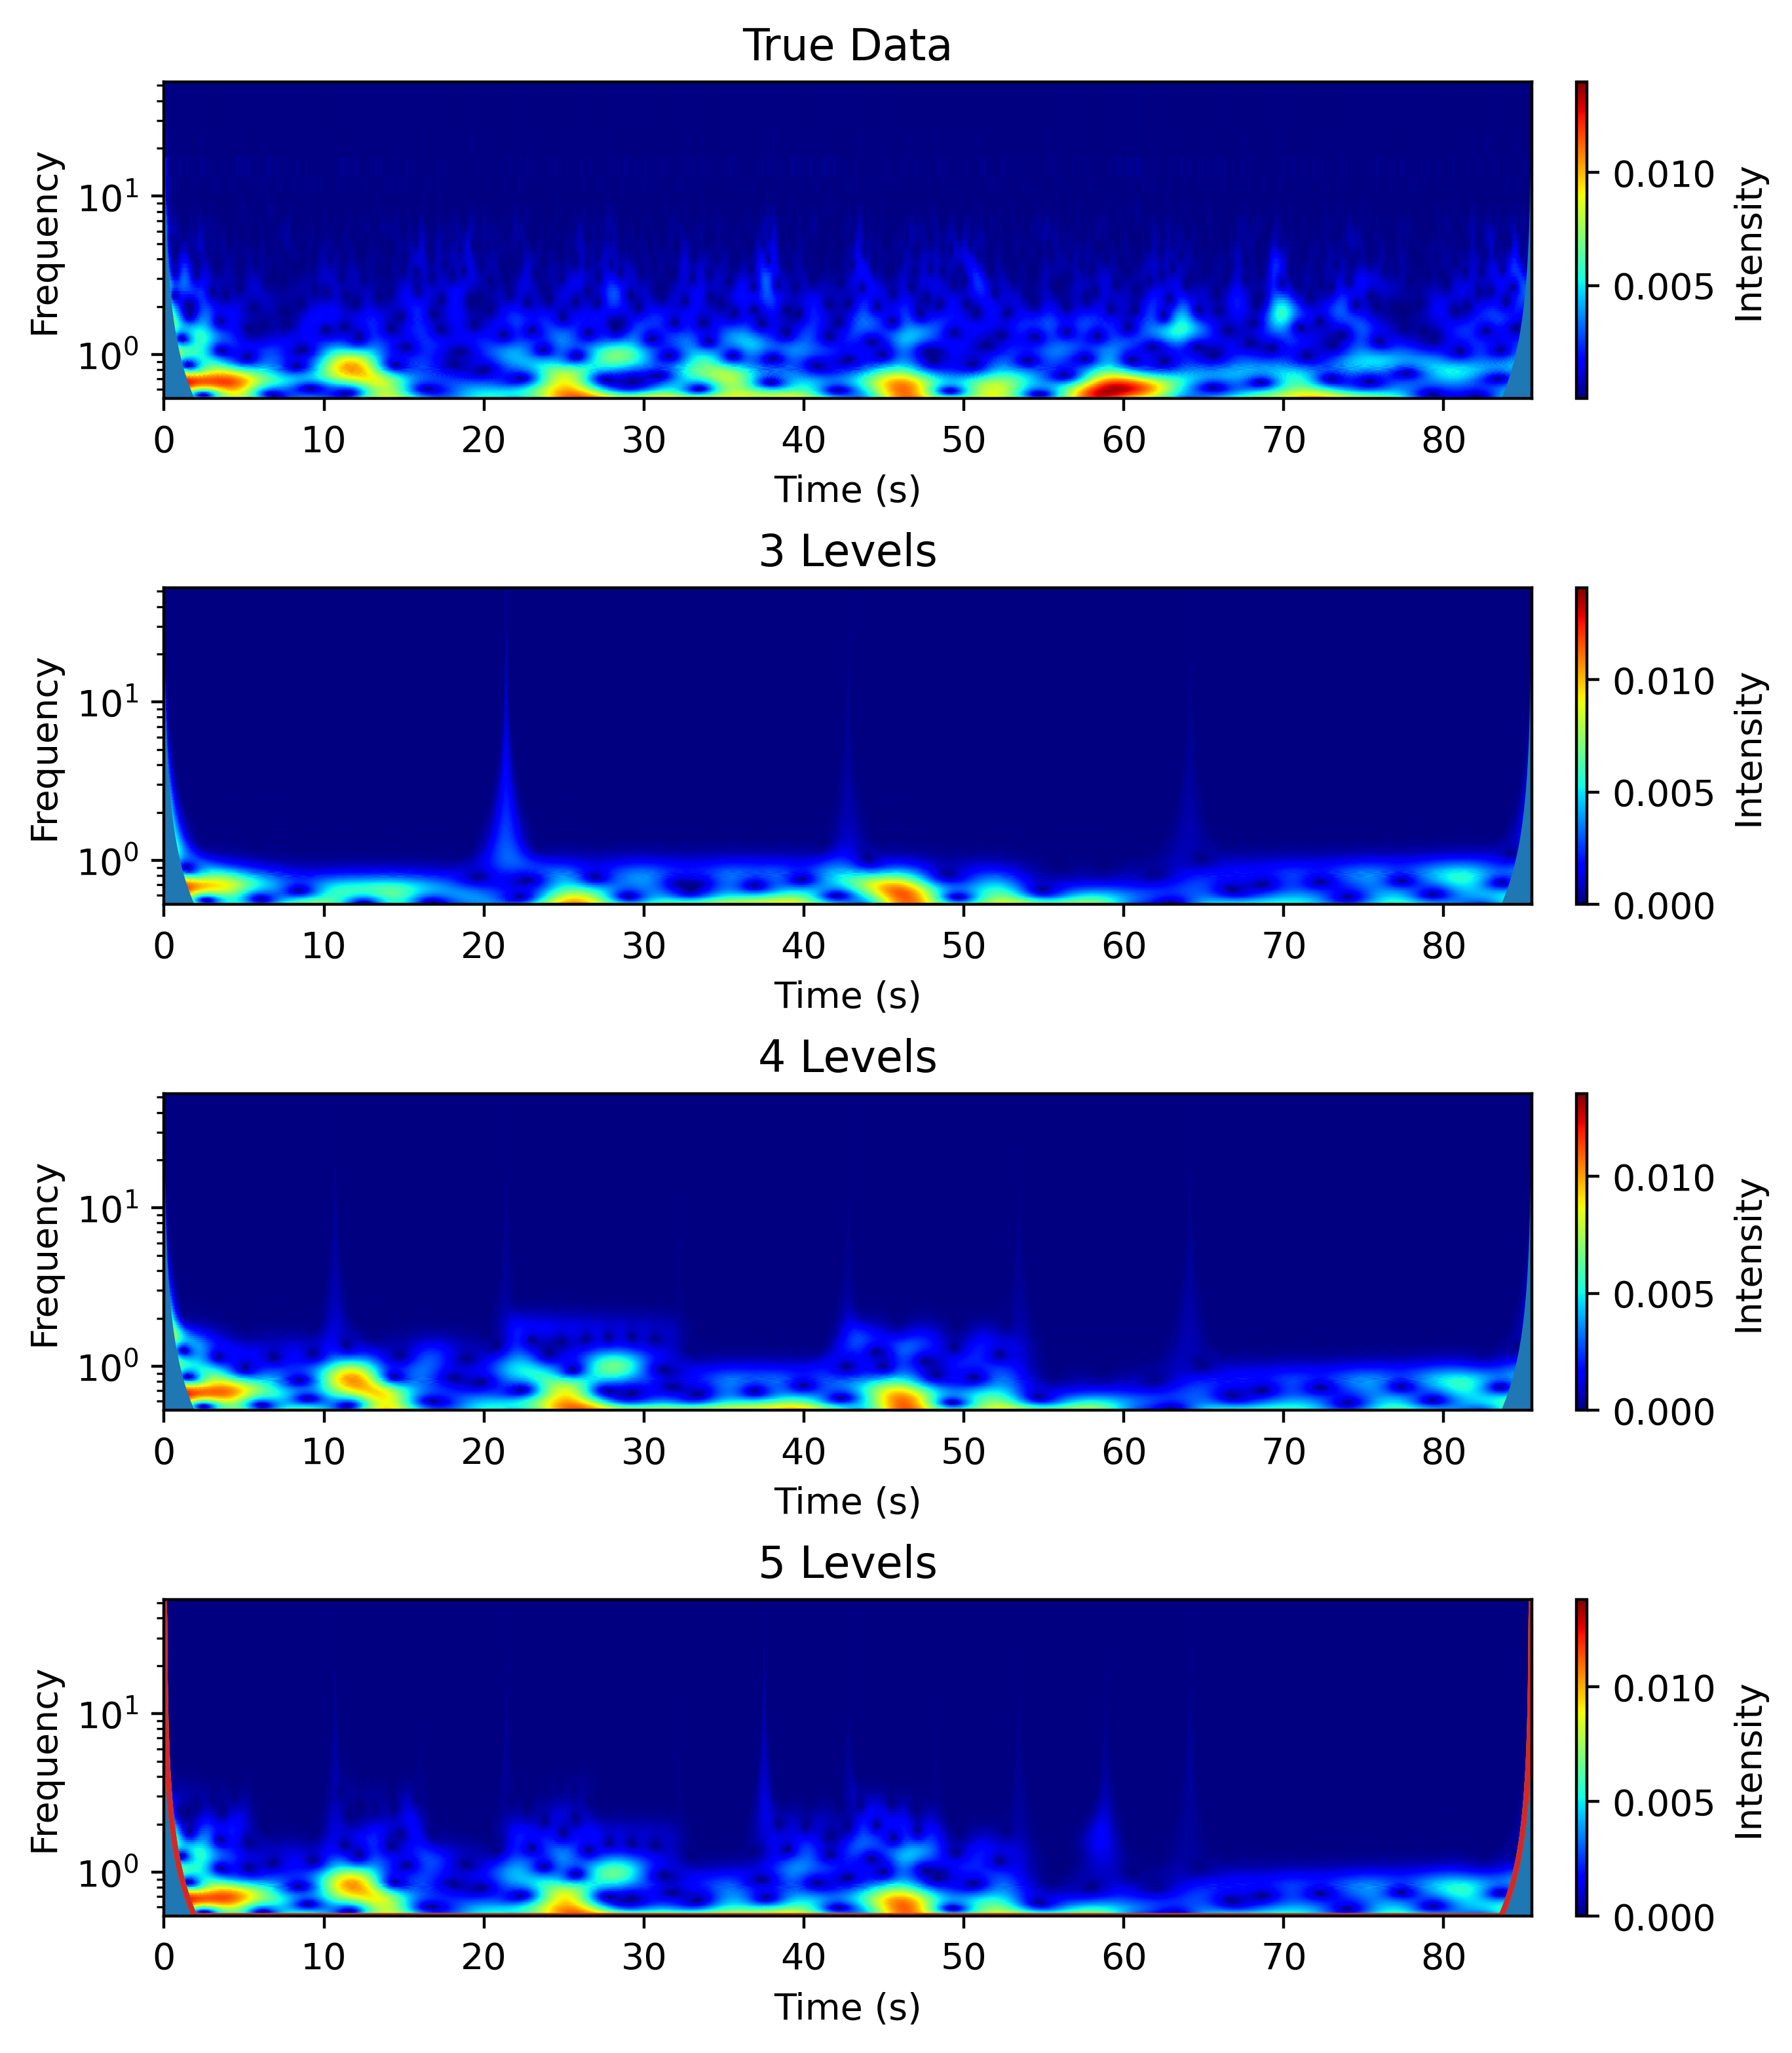

In [5]:
t = np.arange(0,3000*0.0285,0.0285)
fig,ax = plt.subplots(4,1)
fig.tight_layout()
scg.cws(t,SVn[0,:3000],yaxis='frequency',xlabel="Time (s)", title="True Data",cbarlabel="Intensity",ax=ax[0])
scg.cws(t,np.real(mroptdmd_3.reconstructed_data)[0],yaxis='frequency',xlabel="Time (s)", title="3 Levels",cbarlabel="Intensity",ax=ax[1])
scg.cws(t,np.real(mroptdmd_4.reconstructed_data)[0],yaxis='frequency',xlabel="Time (s)", title="4 Levels",cbarlabel="Intensity",ax=ax[2])
scg.cws(t,np.real(mroptdmd_5.reconstructed_data)[0],yaxis='frequency',xlabel="Time (s)", title="5 Levels",cbarlabel="Intensity",ax=ax[3])
fig.subplots_adjust(bottom=-0.5)

To me, this shows that 3 levels is not really enough to fit the higher frequency parts of our data, but 4 levels  probably does a decent job. Note the poles in the reconstructions: these are artifacts of us doing the multiresolution work on discrete windows of data.

The complexity of the model with 4 levels and 24 modes fit on each leaf is really large. The algorithm skips some leaves, but there are still a massive number of modes in total. However, we are able to easily specify how many modes we wish to fit per leaf on each level. Let's try using more modes on upper levels and fewer modes on deeper levels, since intuitively we expect these deeper levels to be fitting transients that consist of probably just a few modes.

In [6]:
mroptdmd_reduced = MrOptDMD([BOPDMD(48),BOPDMD(24),BOPDMD(12),BOPDMD(6)],max_level=3,max_cycles=np.inf,min_cycles=-np.inf)
mroptdmd_reduced.fit(SVn,np.arange(3000))

I'll define the complexity of a MrOptDMD model to be the number of modes divided by 2, since the modes come in complex conjugate pairs.

In [7]:
print("Complexity of Full Model: " + str(len(mroptdmd_4.eigs)//2))
print("Complexity of Reduced Model: " + str(len(mroptdmd_reduced.eigs)//2))
print("Full Model Reconstruction RSE: " + str(RSE(mroptdmd_4.reconstructed_data,SVn)))
print("Reduced Model Reconstruction RSE: " + str(RSE(mroptdmd_reduced.reconstructed_data,SVn)))

Complexity of Full Model: 136
Complexity of Reduced Model: 96
Full Model Reconstruction RSE: 0.023346660665041583
Reduced Model Reconstruction RSE: 0.04072644419898245


This method halves the model complexity but also doubles the reconstruction RSE. However, this RSE is still only 4%, so maybe it's acceptable. Although it appears that with this method we miss a lot of the high frequencies in our data, based on the following scaleogram (compared to the True Data scaleogram above).

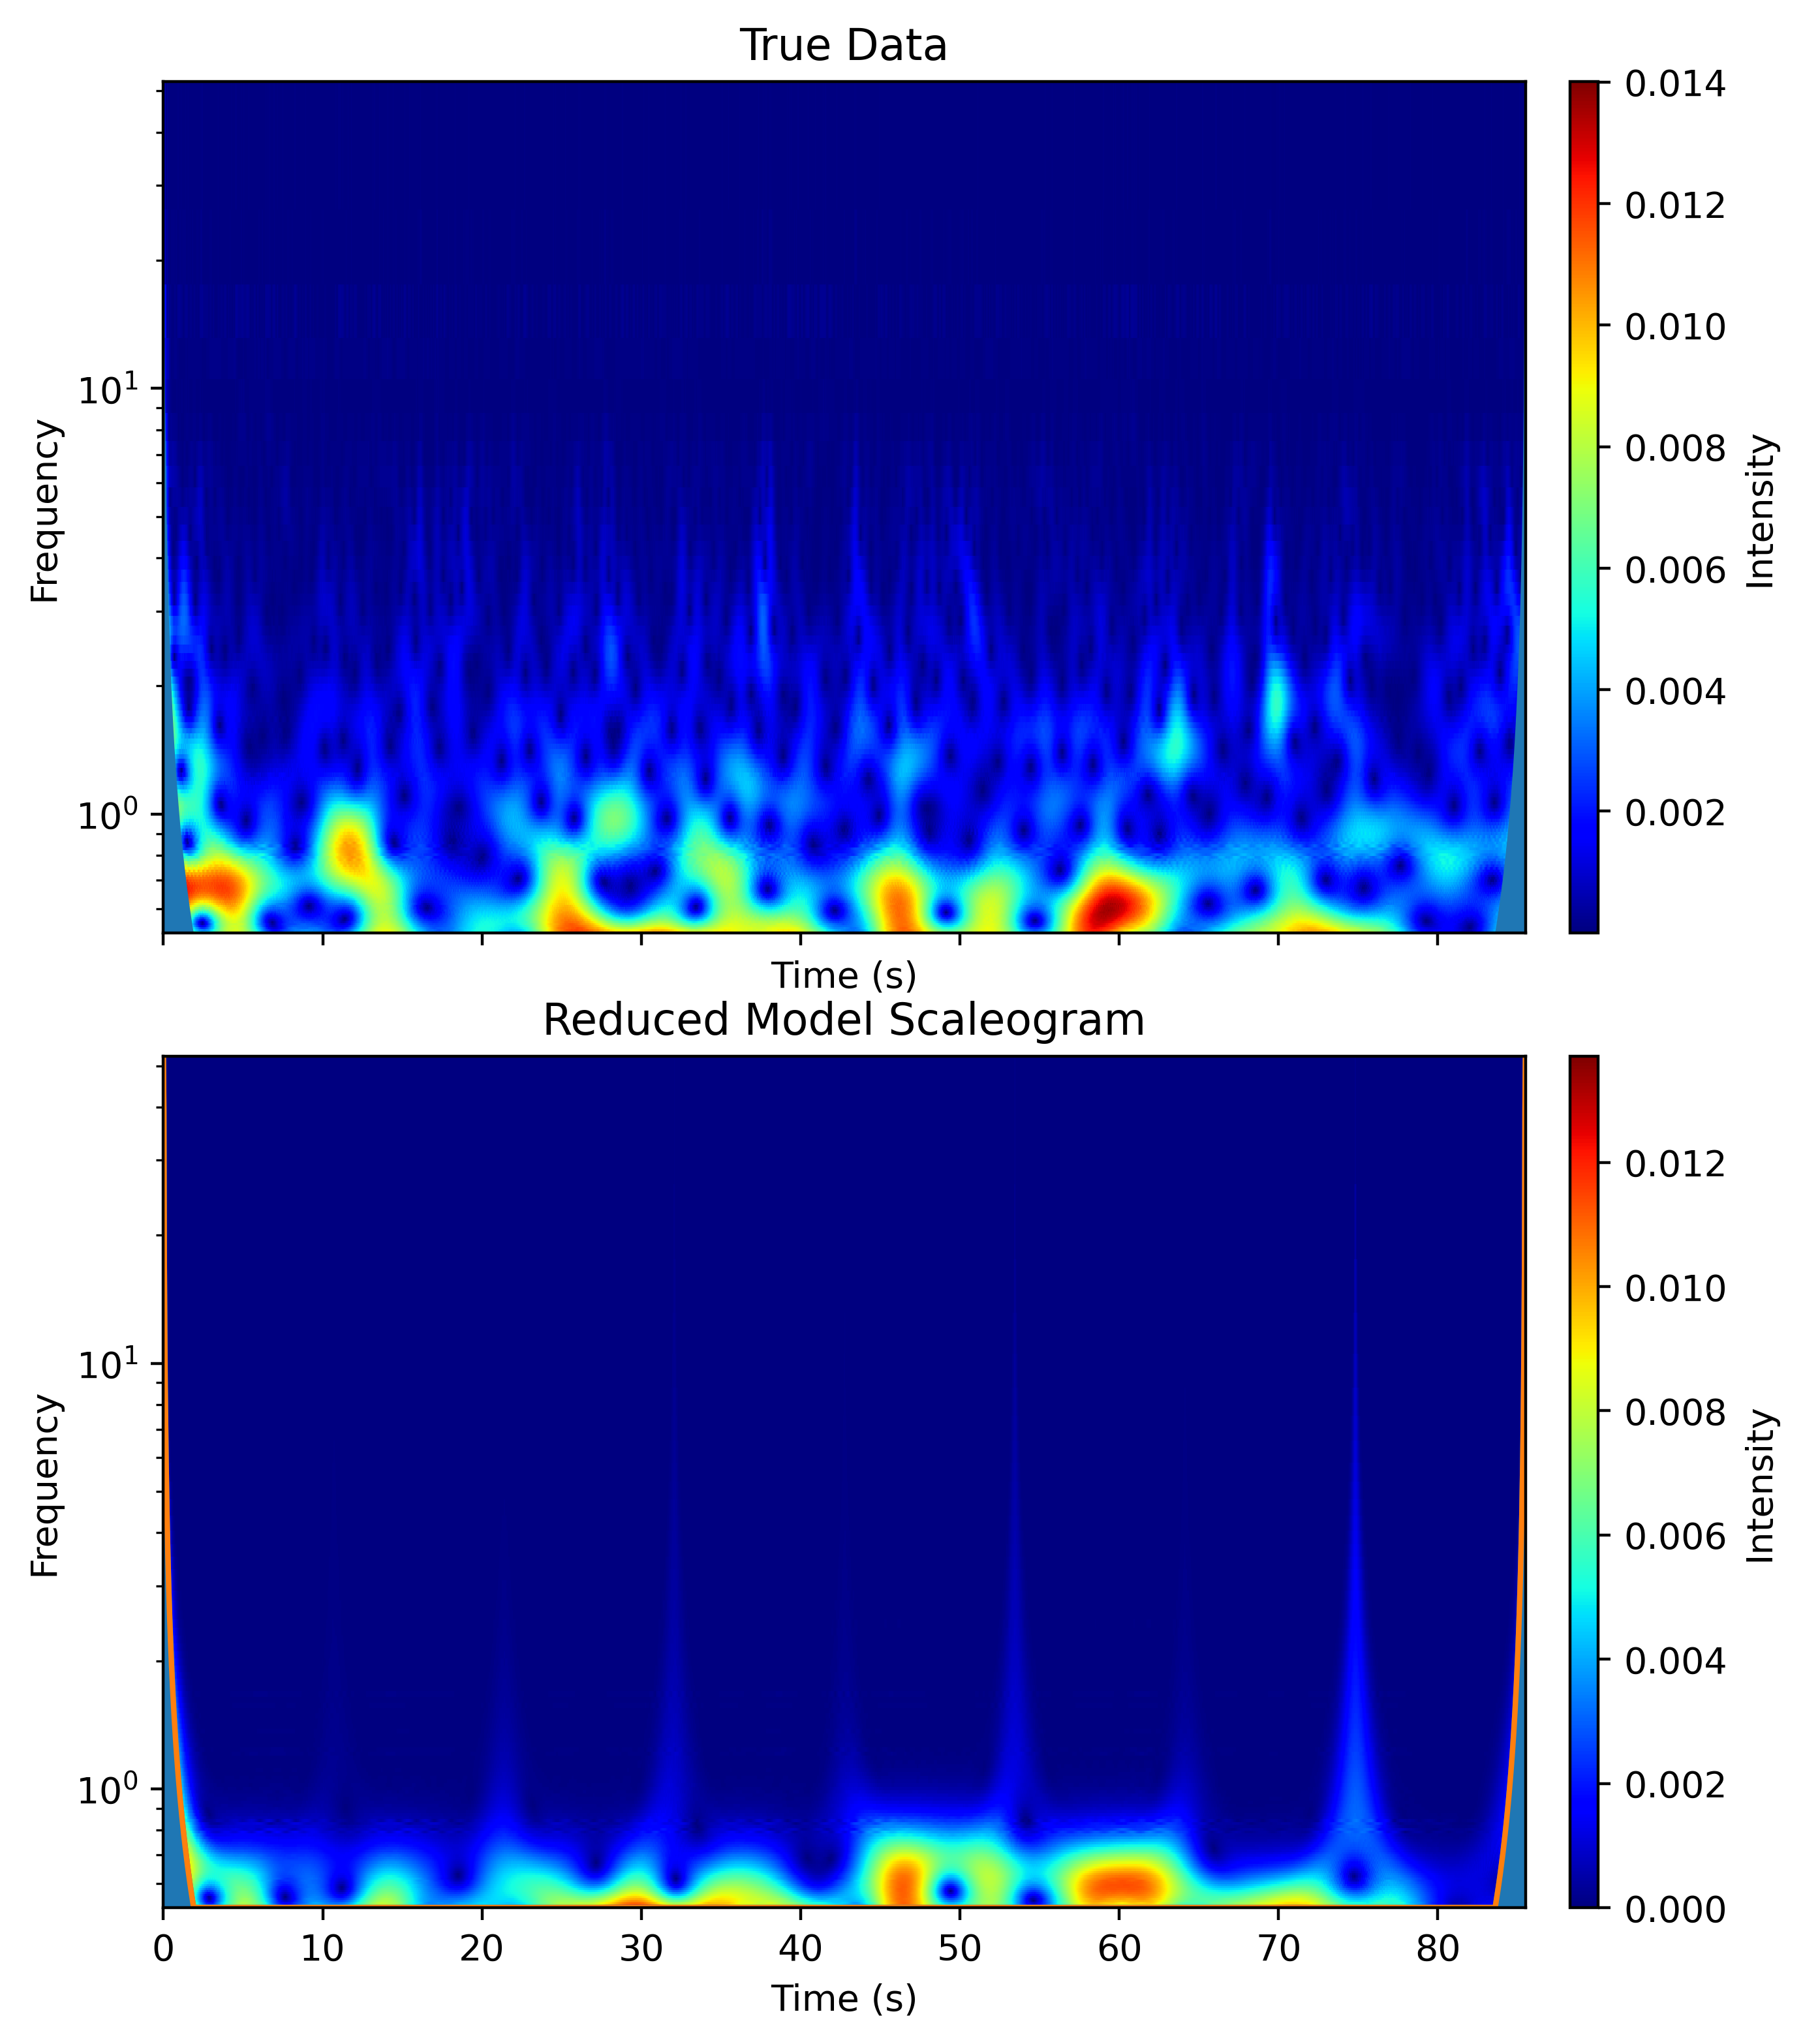

In [8]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
fig.tight_layout()
scg.cws(t,SVn[0,:3000],yaxis='frequency',xlabel="Time (s)", title="True Data",cbarlabel="Intensity",ax=ax[0])
scg.cws(t,np.real(mroptdmd_reduced.reconstructed_data)[0],yaxis='frequency',xlabel="Time (s)",title="Reduced Model Scaleogram",cbarlabel="Intensity",ax=ax[1])
fig.subplots_adjust(bottom=-0.5)

An alternative is to fit more modes on the deepest level but fewer modes on intermediate levels.

In [9]:
mroptdmd_reduced_2 = MrOptDMD([BOPDMD(28),BOPDMD(12),BOPDMD(2),BOPDMD(24)],max_level=3,max_cycles=np.inf,min_cycles=-np.inf)
mroptdmd_reduced_2.fit(SVn,np.arange(3000))

In [10]:
print("Complexity of Full Model: " + str(len(mroptdmd_4.eigs)//2))
print("Complexity of Second Reduced Model: " + str(len(mroptdmd_reduced_2.eigs)//2))
print("Full Model Reconstruction RSE: " + str(RSE(mroptdmd_4.reconstructed_data,SVn)))
print("Second Reduced Model Reconstruction RSE: " + str(RSE(mroptdmd_reduced_2.reconstructed_data,SVn)))

Complexity of Full Model: 136
Complexity of Second Reduced Model: 102
Full Model Reconstruction RSE: 0.023346660665041583
Second Reduced Model Reconstruction RSE: 0.056468668333262424


This method also reduces the model complexity without increasing the reconstruction RSE by much, and also preserves the spectrum to a greater degree.

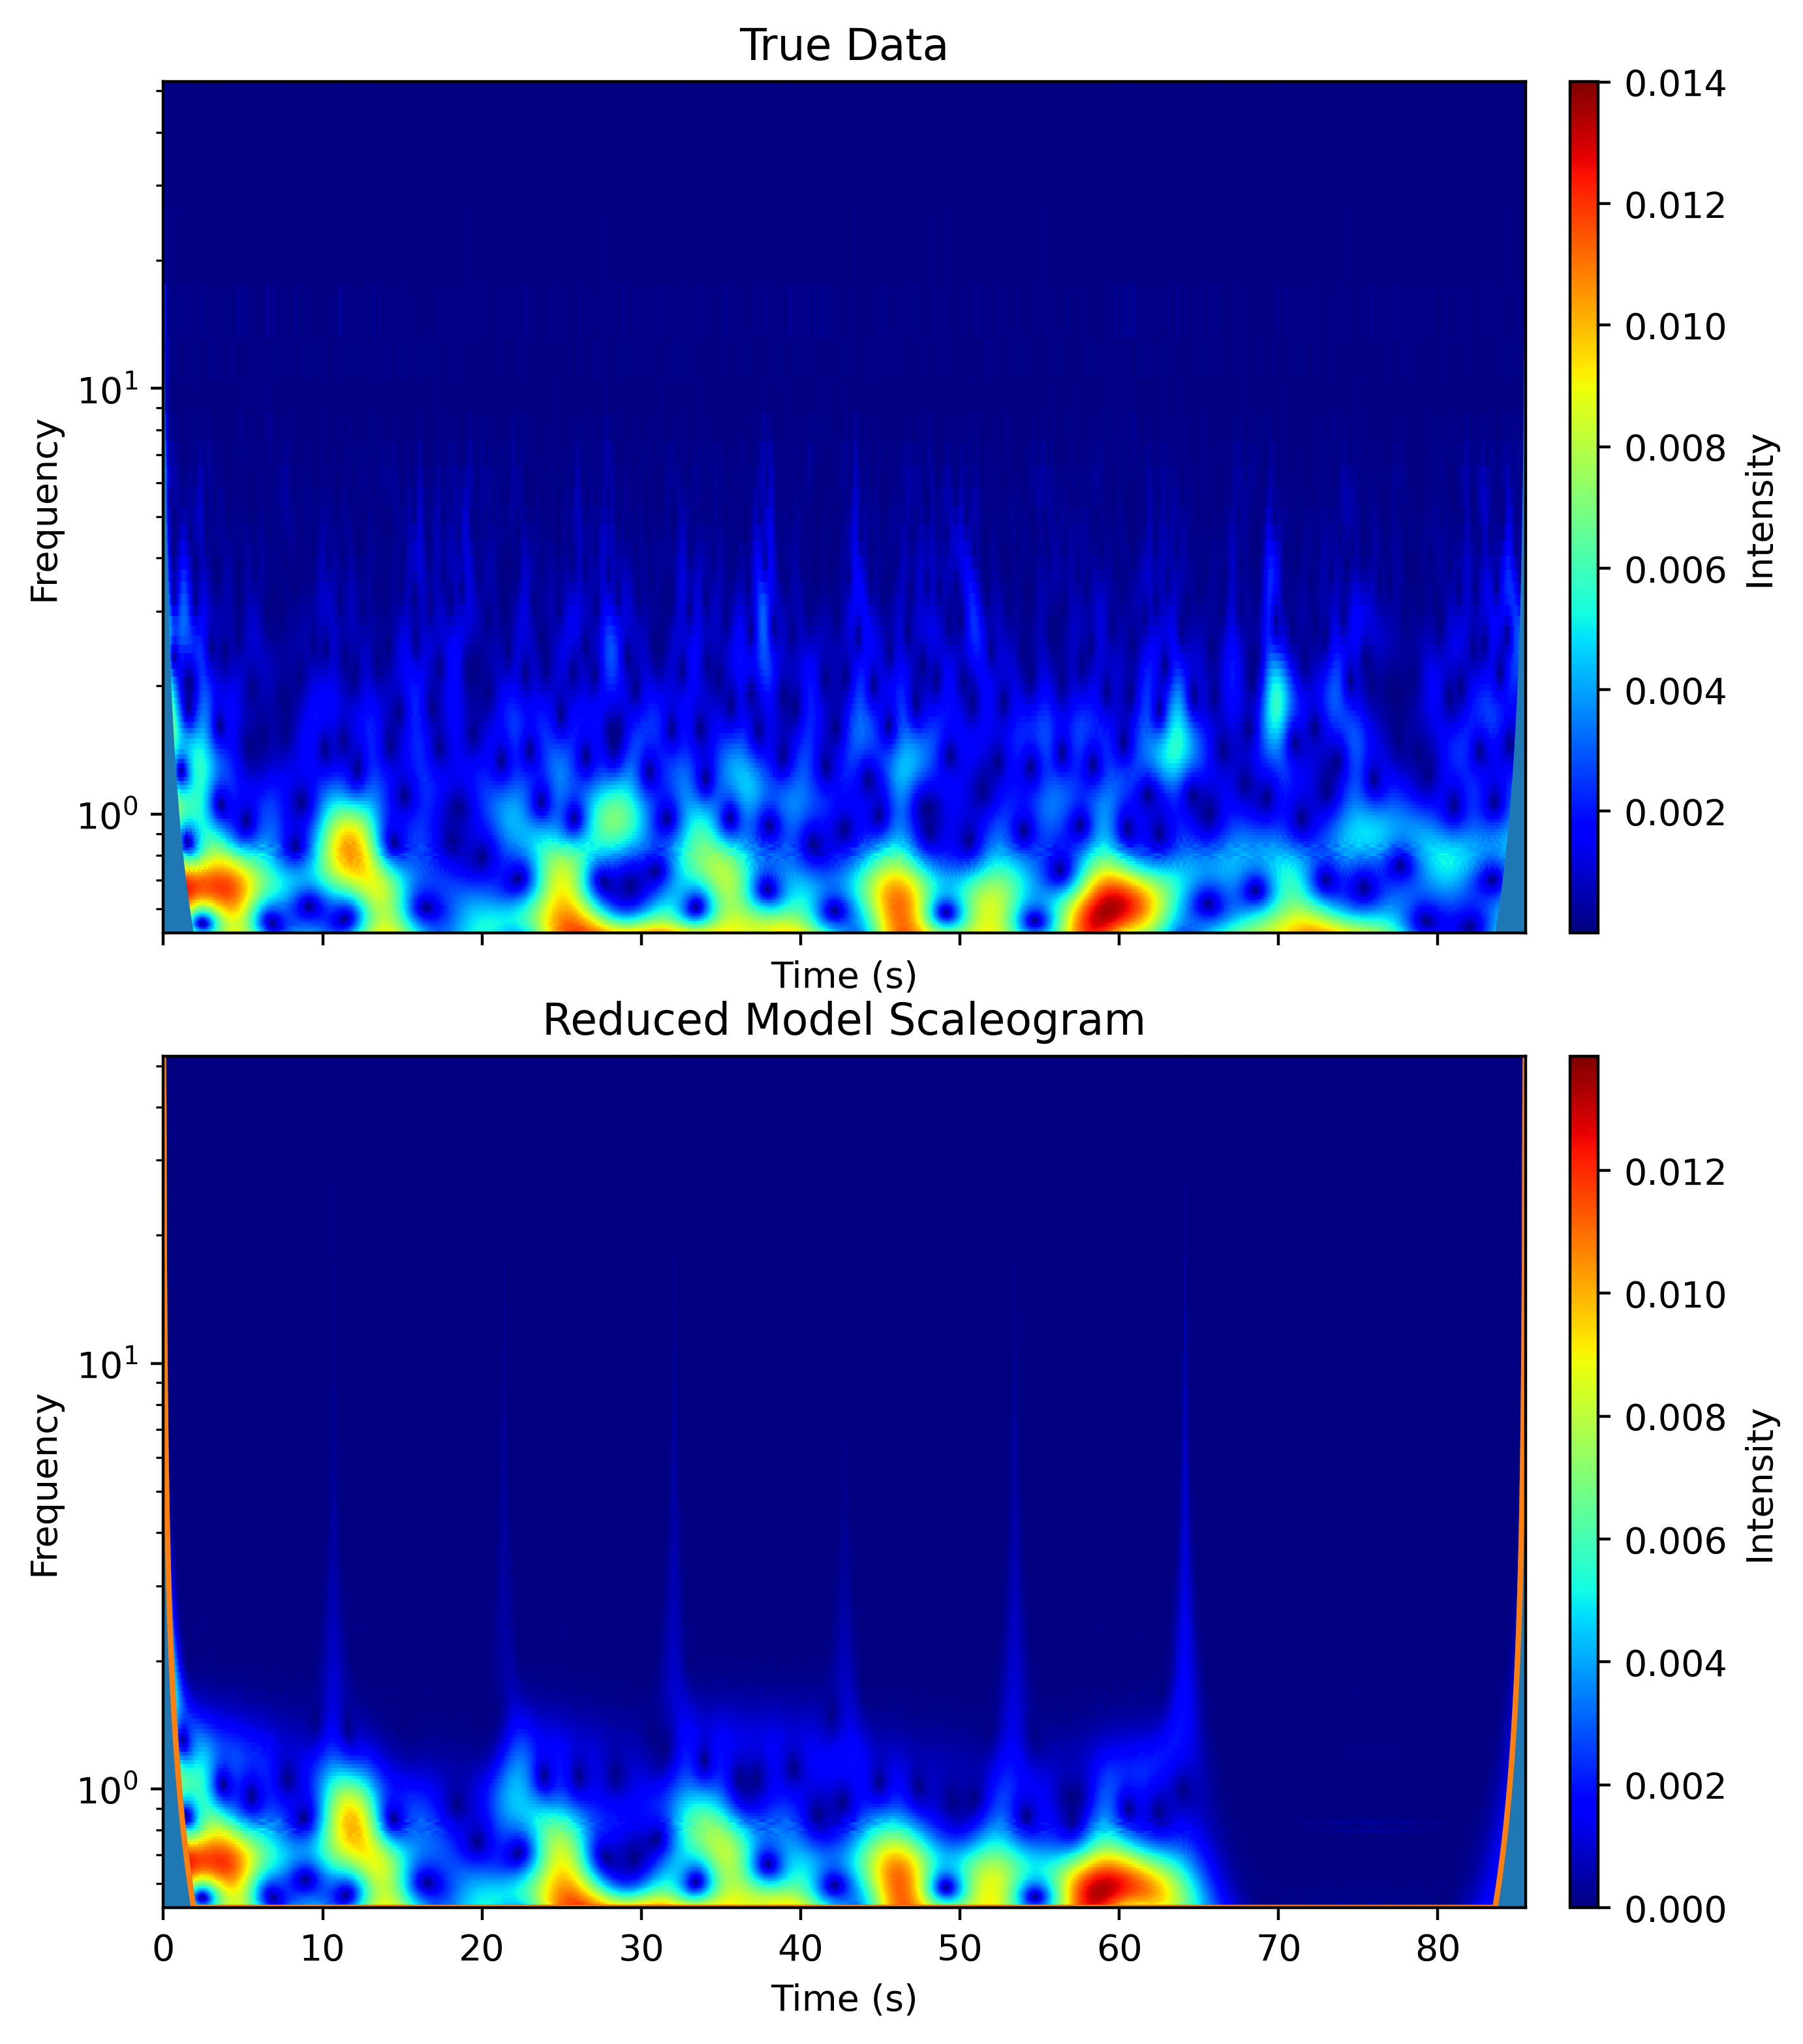

In [11]:
fig,ax = plt.subplots(2,sharex=True,sharey=True)
fig.tight_layout()
scg.cws(t,SVn[0,:3000],yaxis='frequency',xlabel="Time (s)", title="True Data",cbarlabel="Intensity",ax=ax[0])
scg.cws(t,np.real(mroptdmd_reduced_2.reconstructed_data)[0],yaxis='frequency',xlabel="Time (s)",title="Reduced Model Scaleogram",cbarlabel="Intensity",ax=ax[1])
fig.subplots_adjust(bottom=-0.5)

These models all greatly outperform OptDMD alone. Here we fit 50 OptDMD modes to the original 50 widefield modes, so this is the greatest OptDMD performance can be.

In [12]:
optdmd = BOPDMD(50)
optdmd.fit(SVn,np.arange(3000))
print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data,SVn)))

OptDMD RSE: 0.20538053592887884


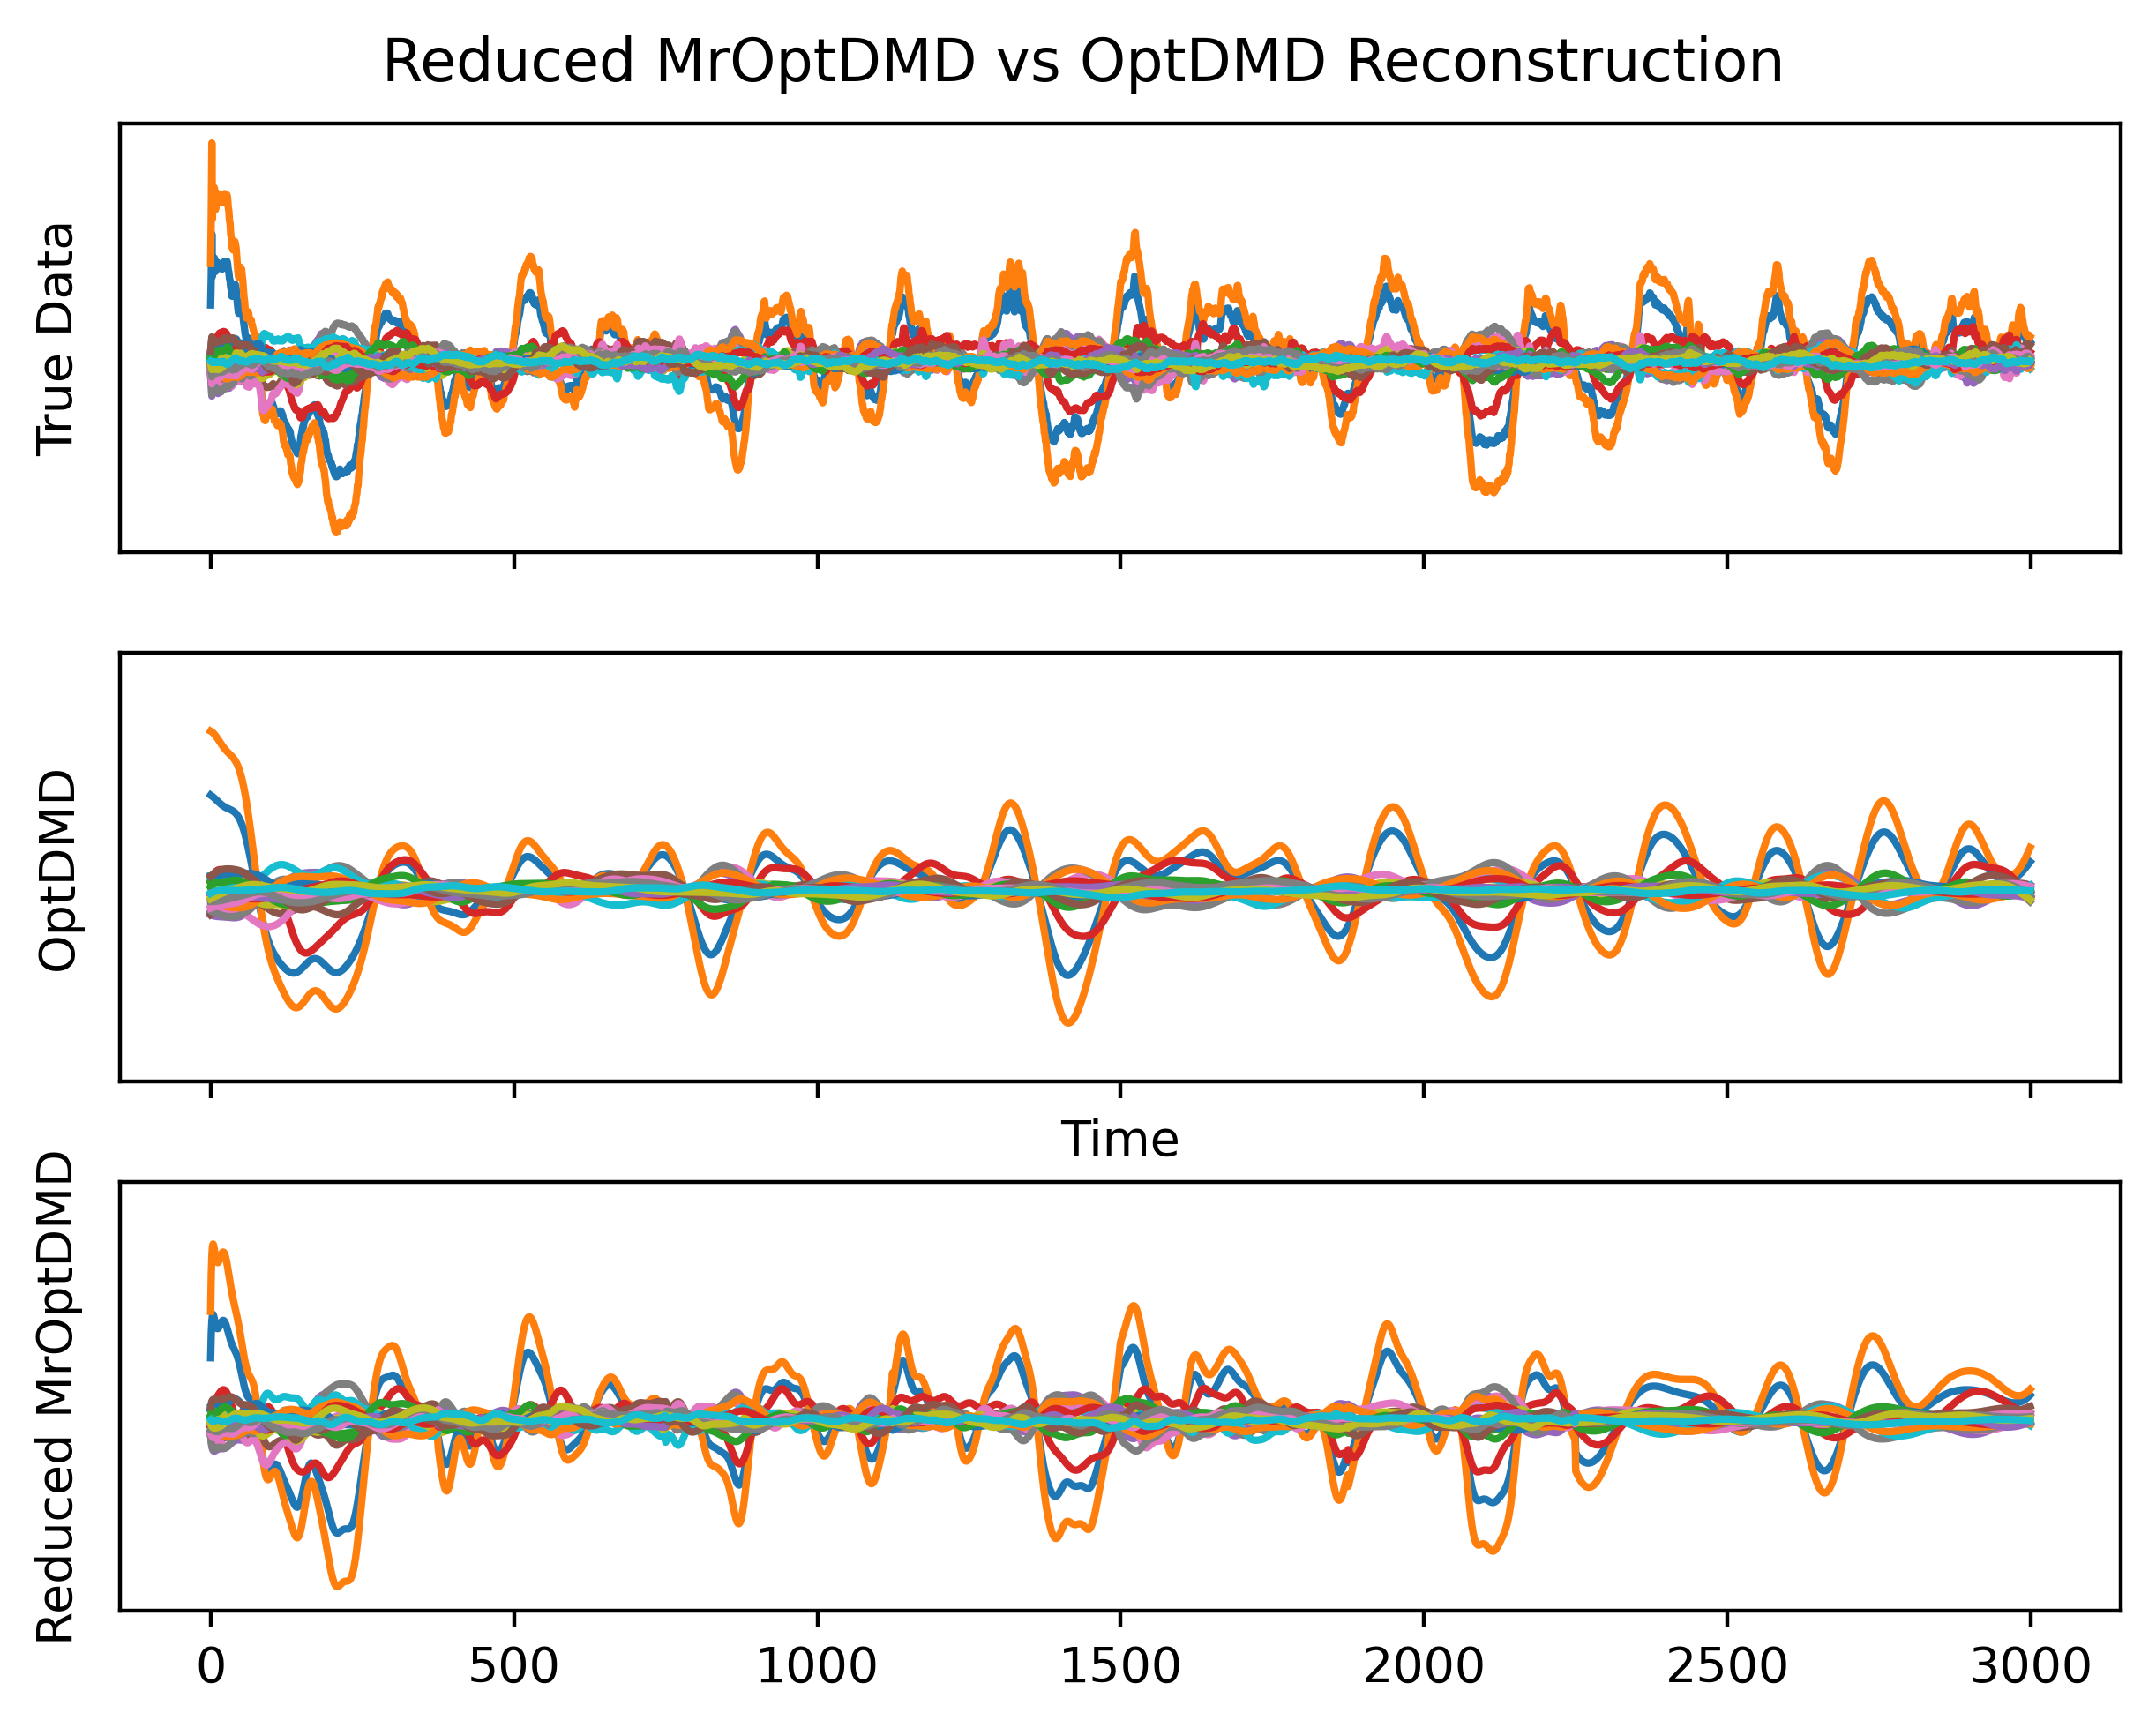

In [13]:
fig,ax = plt.subplots(3,1,sharex=True,sharey=True)
fig.tight_layout()
for i in range(20):
    ax[0].plot(SVn[i])
    ax[1].plot(np.real(optdmd.reconstructed_data)[i])
    ax[2].plot(np.real(mroptdmd_reduced_2.reconstructed_data)[i])
ax[0].set_yticks([])
ax[0].set_ylabel("True Data")
ax[1].set_ylabel("OptDMD")
ax[2].set_ylabel("Reduced MrOptDMD")
ax[1].set_xlabel("Time")
fig.suptitle("Reduced MrOptDMD vs OptDMD Reconstruction",y=1.01);

From the smooth peaks in the OptDMD fit, we can see that the difference in performance between MrOptDMD and OptDMD comes from MrOptDMD's ability to pick out transient fluctuations. Of course, these fluctuations are probably noise in many cases, so perhaps this MrOptDMD model still has too much complexity.

Next we can look at the contributions of each level.

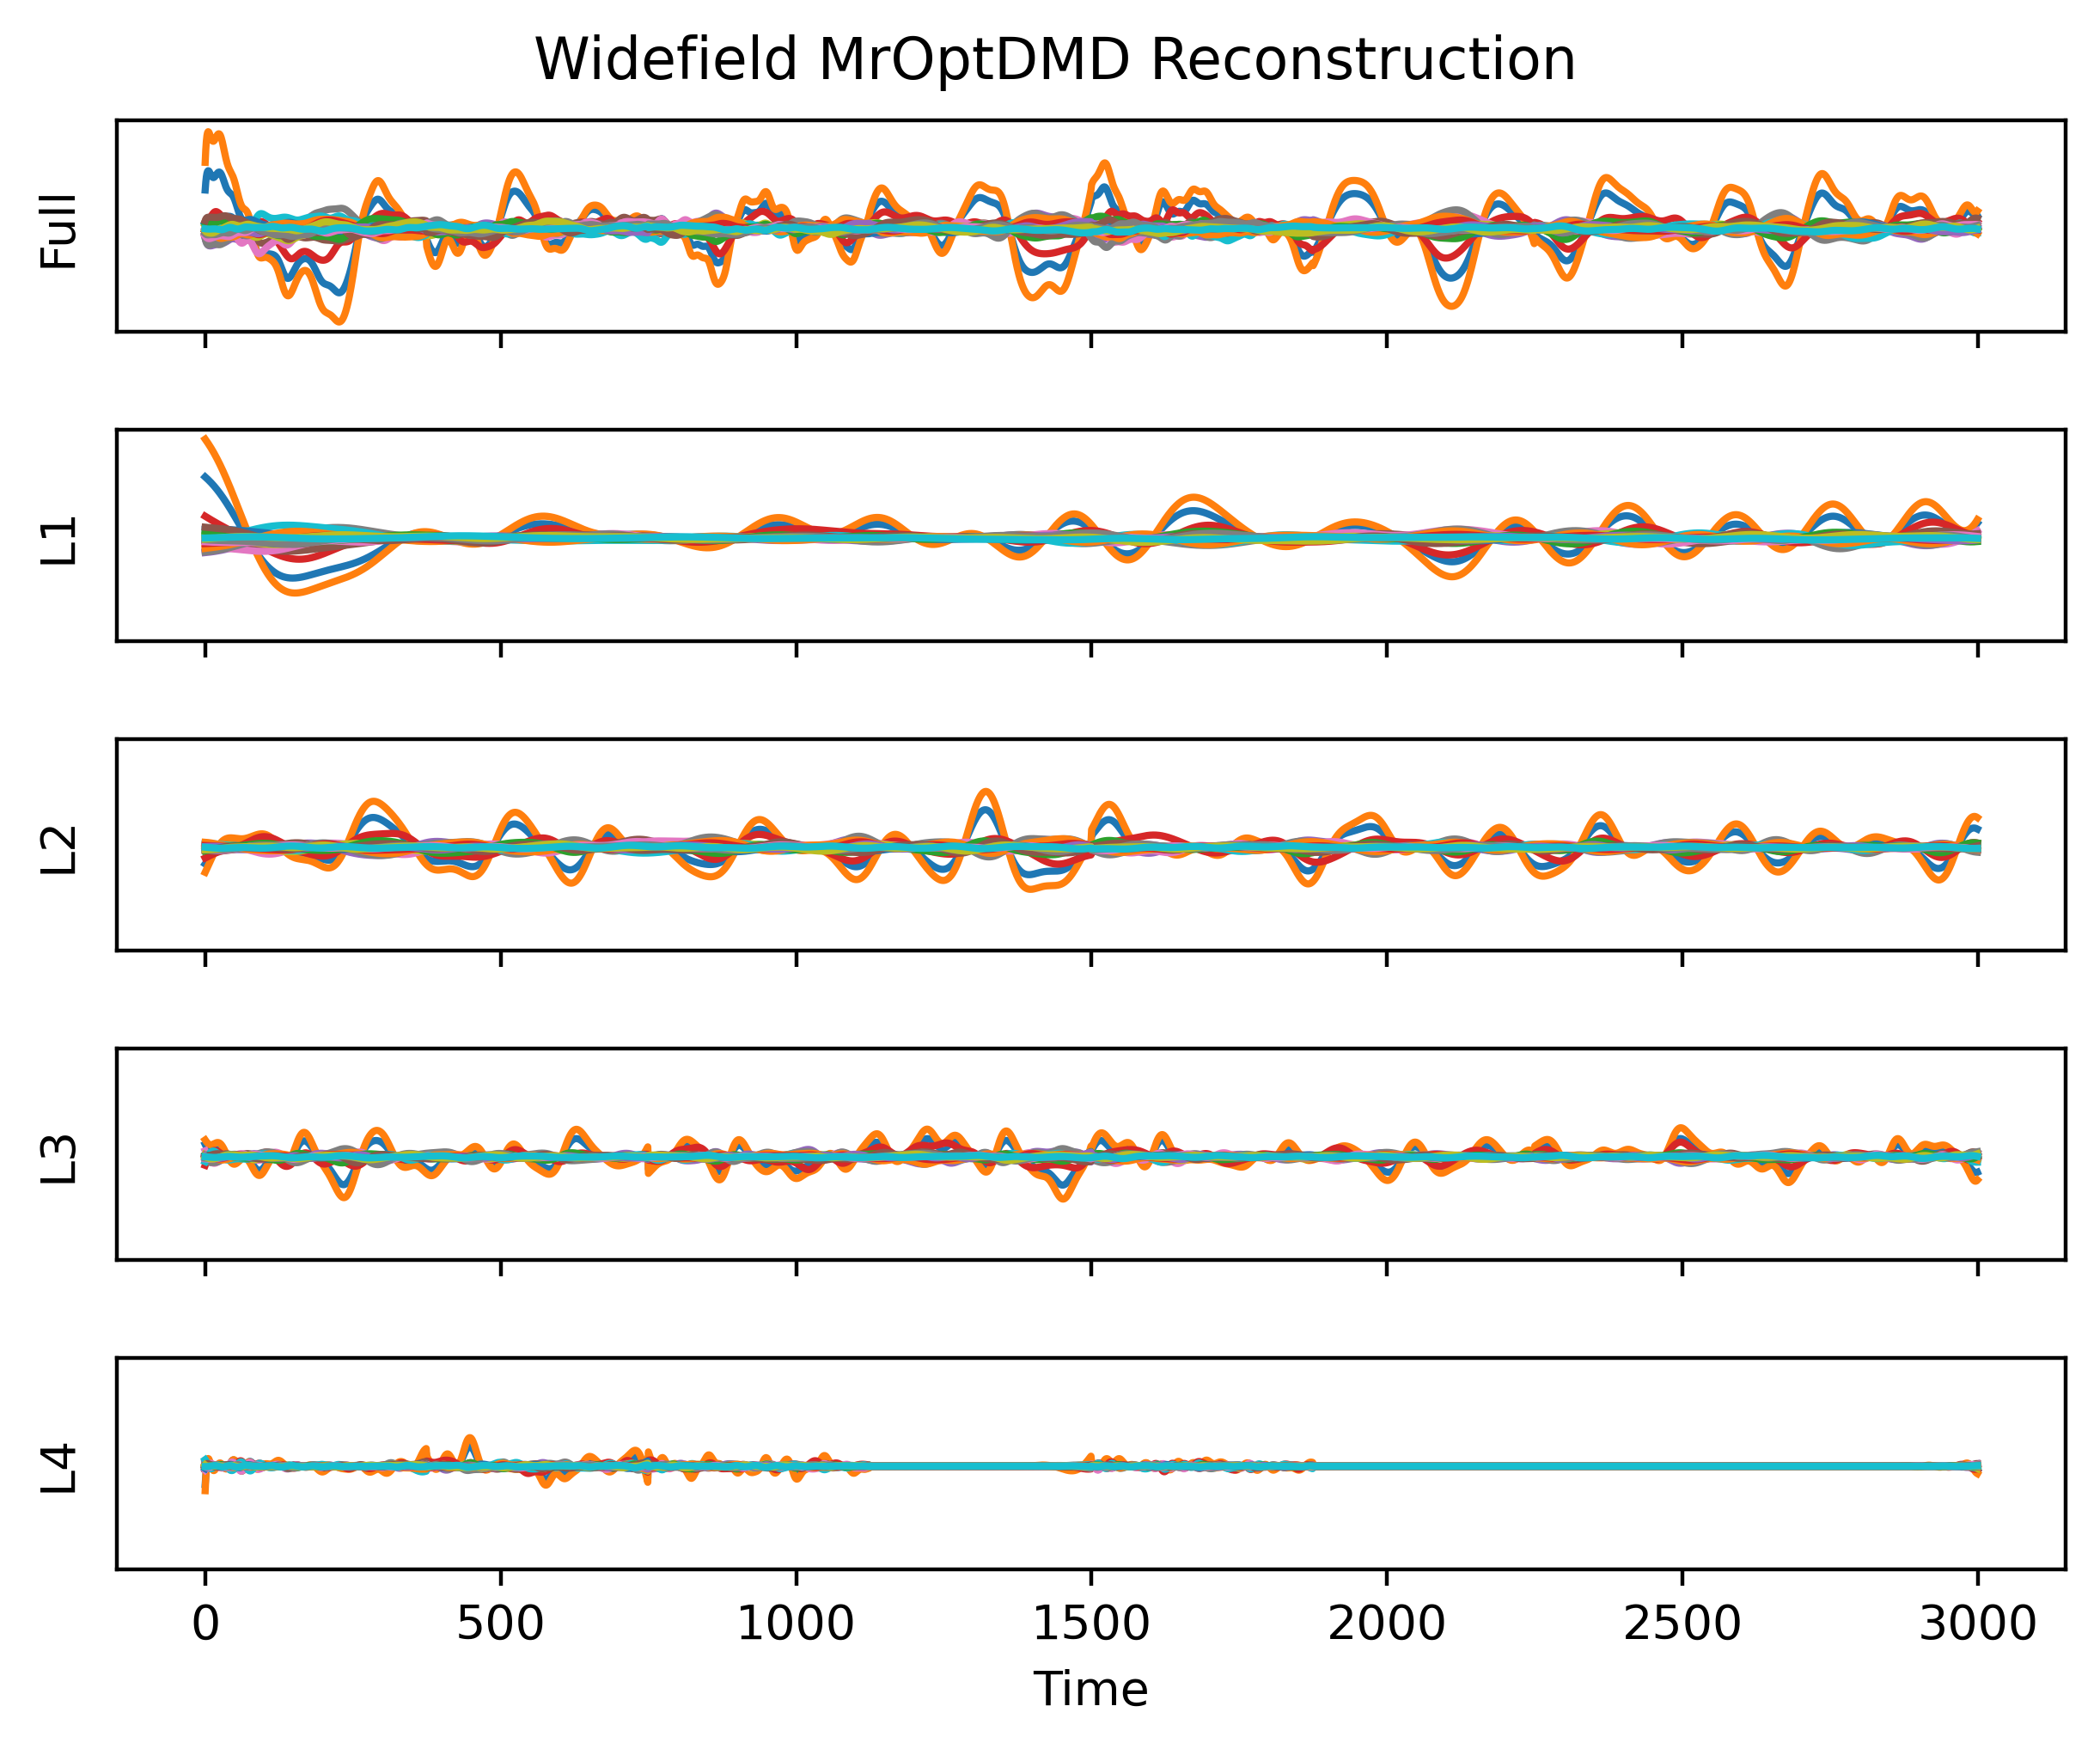

In [14]:
fig,ax=plt.subplots(5,1,sharex=True,sharey=True)
fig.tight_layout()
for i in range(20):
    ax[0].plot(np.real(mroptdmd_4.reconstructed_data)[i])
    ax[0].set_ylabel("Full")
    for j in range(4):
        ax[j+1].plot(np.real(mroptdmd_4.partial_reconstructed_data(j))[i])
        ax[j+1].set_ylabel("L" + str(j+1))
ax[4].set_xlabel("Time")
ax[4].set_yticks([])
fig.suptitle("Widefield MrOptDMD Reconstruction",y=1.01);

It appears to me like level four is mostly noise, so maybe the higher frequencies that the model with level four is capturing are just noise.

Next we can look at the eigenvalues at each level. I have colored the eigenvalues by their level (blue, orange, green, and red corresponding to levels 1, 2, 3, and 4 respectively) and visually scaled them by the cube root of their amplitudes. The point of this scaling is to help us visualize all eigenvalues simultaneously, since some have massive amplitudes while some have very small amplitudes.

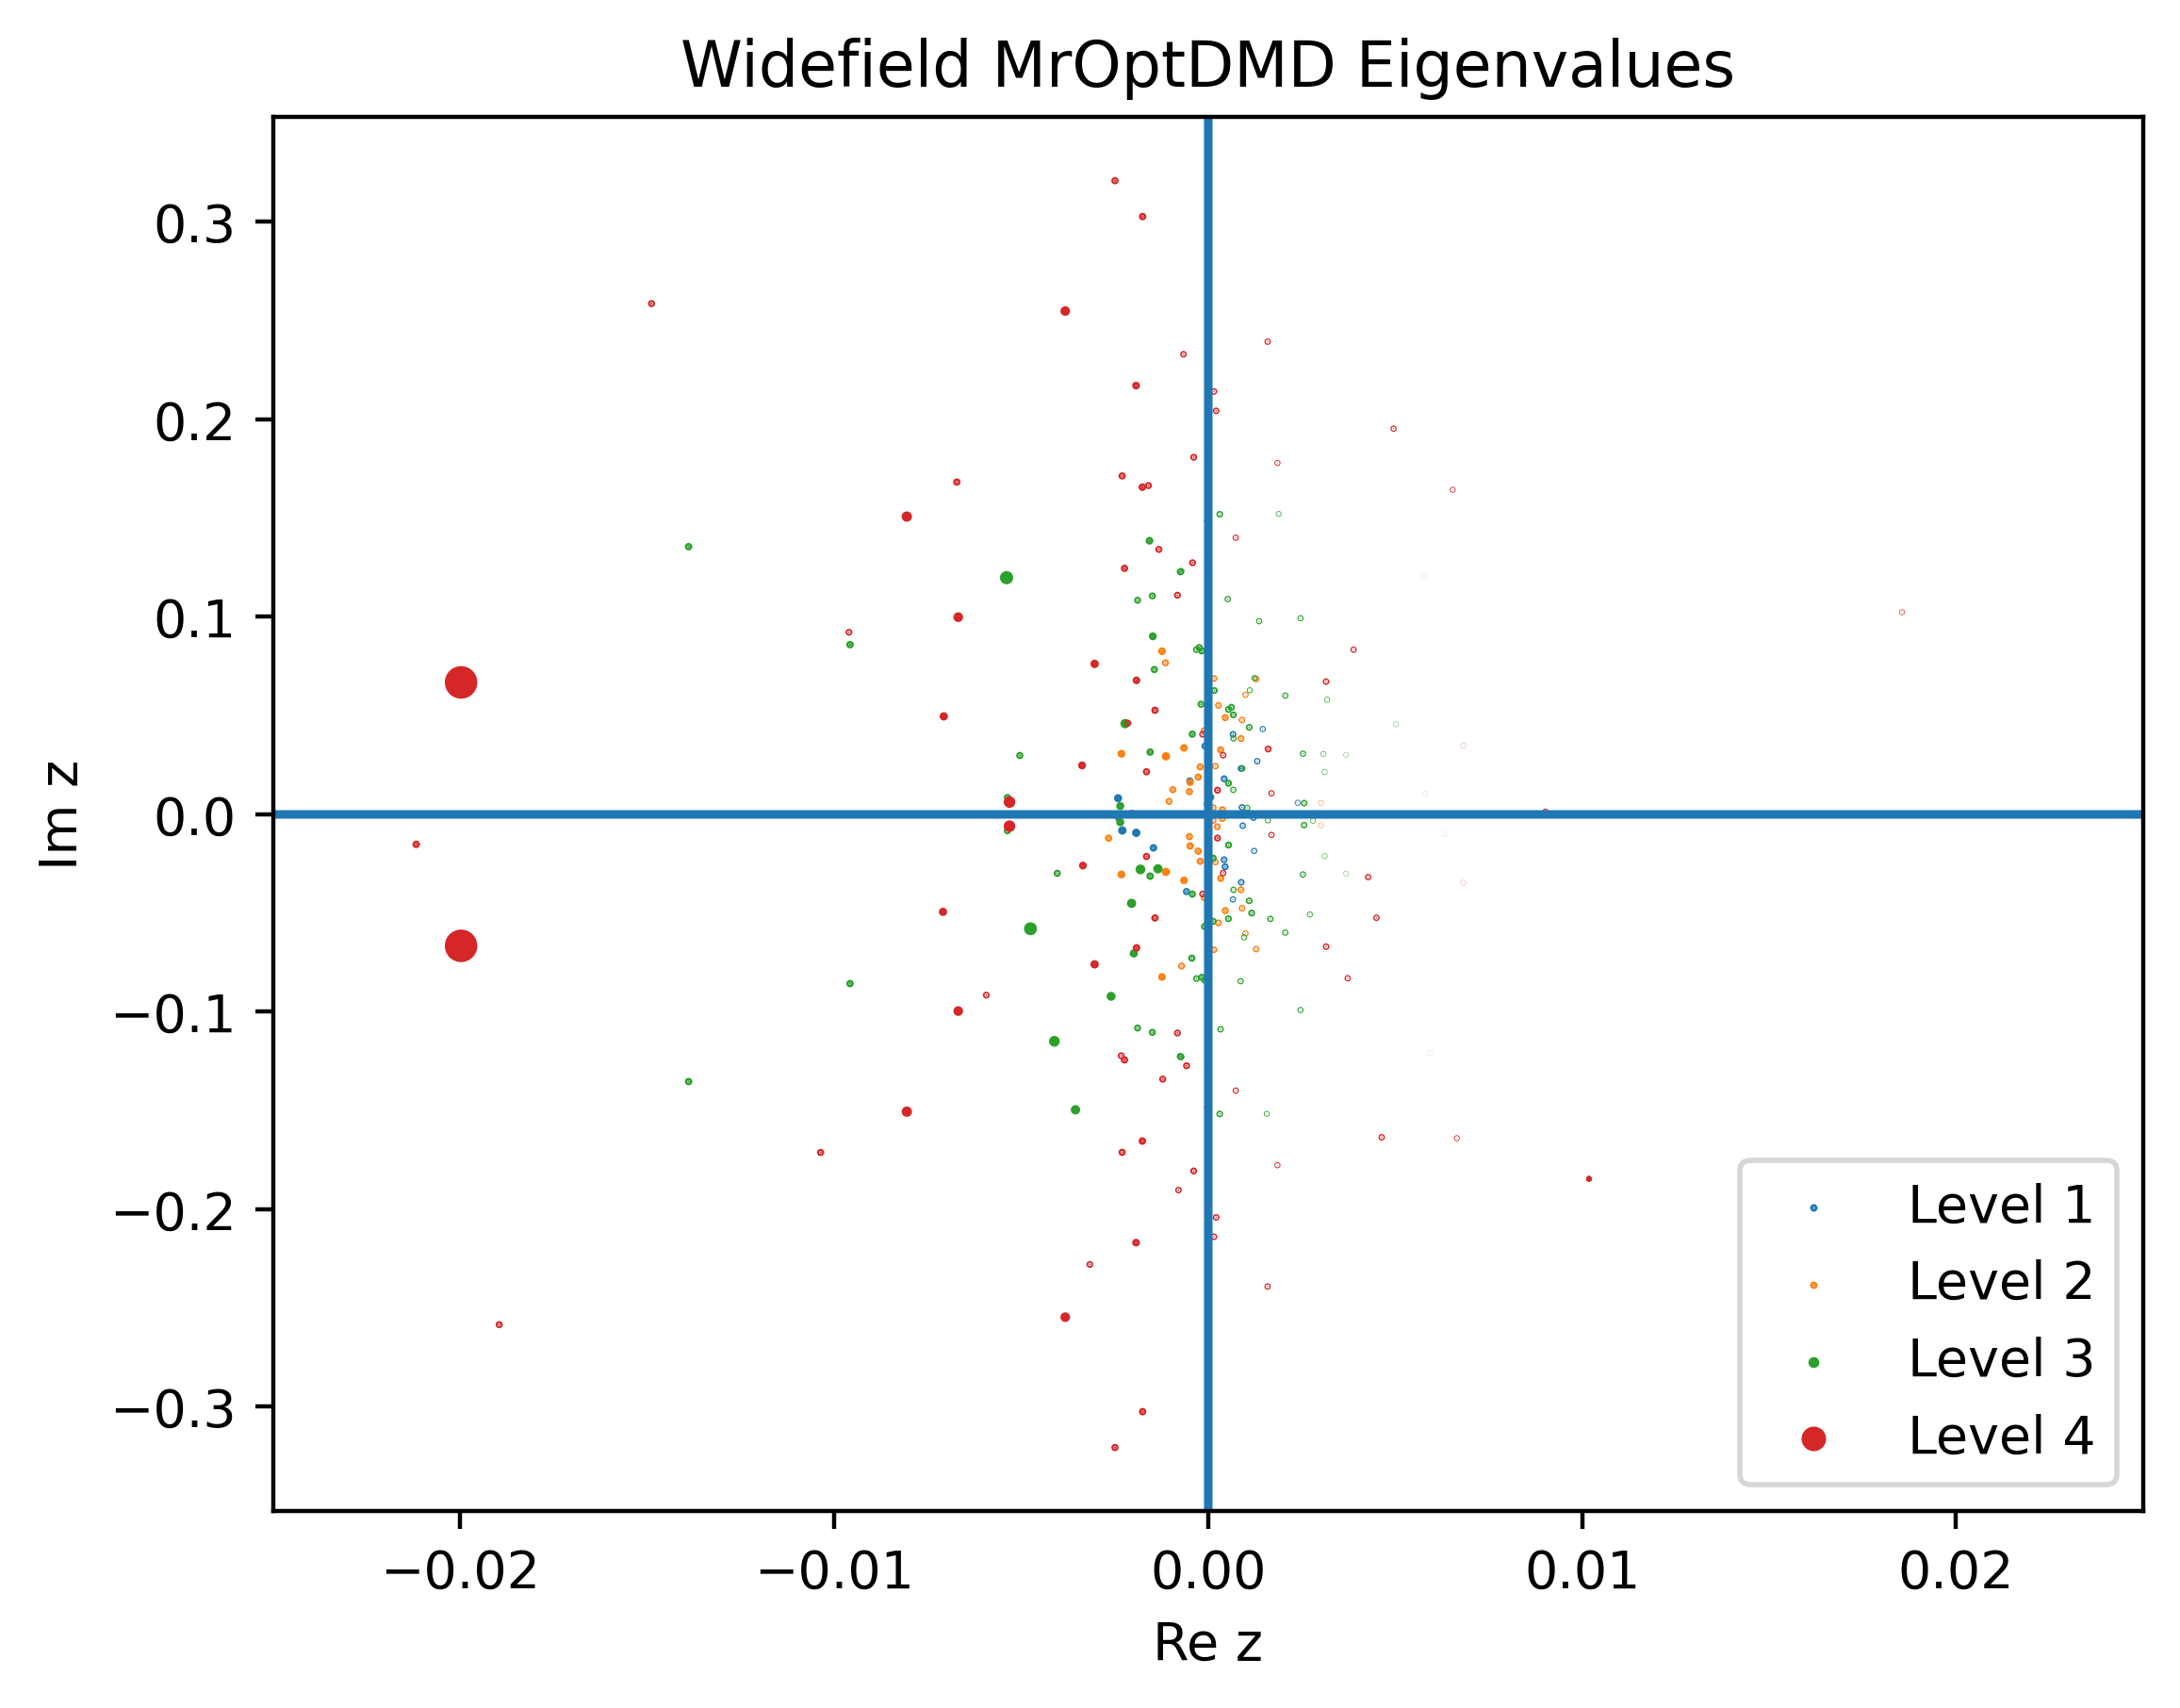

In [15]:
for i in range(4):
    plt.scatter(np.real(mroptdmd_4.partial_eigs(i)),np.imag(mroptdmd_4.partial_eigs(i)),label="Level " + str(i+1),alpha=1,s=(mroptdmd_4.partial_amplitudes(i))**(1/3))
    #plt.plot(np.real(mroptdmd.partial_eigs(i)),np.imag(mroptdmd.partial_eigs(i)),'o',label="Level " + str(i+1),alpha=0.3)
    plt.xlabel("Re z")
    plt.ylabel("Im z")
    plt.axhline(0)
    plt.axvline(0)
plt.legend()
plt.xlim(-0.025,0.025)
plt.title("Widefield MrOptDMD Eigenvalues");

As we can see, deeper levels find higher frequency modes (i.e. higher eigenvalues greater imaginary part). However, they find some low frequencies as well. I have found that filtering these out during the fit can lead to poor accuracy. It's easy to filter out these low frequencies for analysis after doing the fit though. The deeper levels also have larger real parts in absolute value. Presumably this is because the eigenvalues need to grow or shrink rapidly in a short time window.

Unsurprisingly, eigenvalues with positive real part have very low amplitude, so that they start out small and reach a relevant size by the end of the trial. The opposite is true for eigenvalues with negative real part: many start out large and shrink down.

Finally, we can do a quick test with MrDMD, and demonstrate that with the exact same parameters as we used for MrOptDMD, it fails.

In [16]:
dmd = DMD(svd_rank=24)
mrdmd_test = pydmd.MrDMD(dmd,max_level=4,max_cycles=np.inf)
mrdmd_test.fit(SVn)
RSE(np.real(mrdmd_test.reconstructed_data),SVn)

/home/msw1/.local/lib/python3.11/site-packages/pydmd/mrdmd.py:500: ComplexWarning: Casting complex values to real discards the imaginary part
  ).astype(X.dtype)


1.395168081461798

So we get 140% reconstruction RSE with MrDMD.

# Natural Image Widefield

I used MrOptDMD to fit the entire mouse natural image experiment. I used 24 modes on every level and every level.

In [17]:
import pickle

SV_NI = np.load('../Mouse Data/svdTemporalComponents_corr.npy')[5480:58555,:50].T
SV_NI_norm = np.linalg.norm(SV_NI)
SV_NI_n = SV_NI / SV_NI_norm

file = open('../Processed Data and Results/mroptdmd_NI.pkl', 'rb')
mroptdmd_NI = pickle.load(file)
file.close()

print("Natural Image MrOptDMD Error: " + str(RSE(mroptdmd_NI.reconstructed_data,SV_NI_n)))
del SV_NI

Natural Image MrOptDMD Error: 0.2325118931011938


Based on this error, I may need to fit it again with different parameters. Still, I will leave it here to show that we may be able to fit large datasets with MrOptDMD and analyze the fit.

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]



In [18]:
fig,ax = plt.subplots(11,1,sharex=True,sharey=True)
for i in tqdm(range(10),leave=False):
    ax[0].plot(SV_NI_n[i,:])
    ax[0].set_yticks([])
    ax[0].set_ylabel("True Data")
    for j in tqdm(range(10),leave=False):
        ax[i+1].plot(np.real(mroptdmd_NI.partial_reconstructed_data(i)[j,:]))
        ax[i+1].set_ylabel("L" + str(i+1))
fig.set_figheight(30)
fig.set_figwidth(15)
fig.suptitle("MrOptDMD Level Decomposition of Natural Image Experiment",y=0.95);

# Synthetic Data

Does MrOptDMD find the "true" modes in data? The answer is yes, if we give it the right hyperparameters. This portion of the notebook will show this. We will create a simple toy example where we know what the temporal and spatial modes should be and show that MrOptDMD can recover them.

In [19]:
tspan = np.linspace(0,40,400)
mode3 = np.cos(np.pi/8*np.linspace(0,40,400)) # zero 30s, sinusoid 10s # freq = pi/8
mode2 = np.append(np.zeros(200),np.cos(1/4*np.pi*np.linspace(0,20,200))) # freq = pi/4
mode1 = np.append(np.cos(np.pi*np.linspace(0,10,100)),np.zeros(300)) # freq = pi
spat_mode = np.cos(np.pi/6*np.linspace(0,40,400))
np.random.seed(1)
test_data_noise_free = np.outer(spat_mode,(mode1+mode2+mode3))
test_data = np.outer(spat_mode,(mode1+mode2+mode3))+np.random.rand(400,400)

Here is a visualization of the temporal modes.

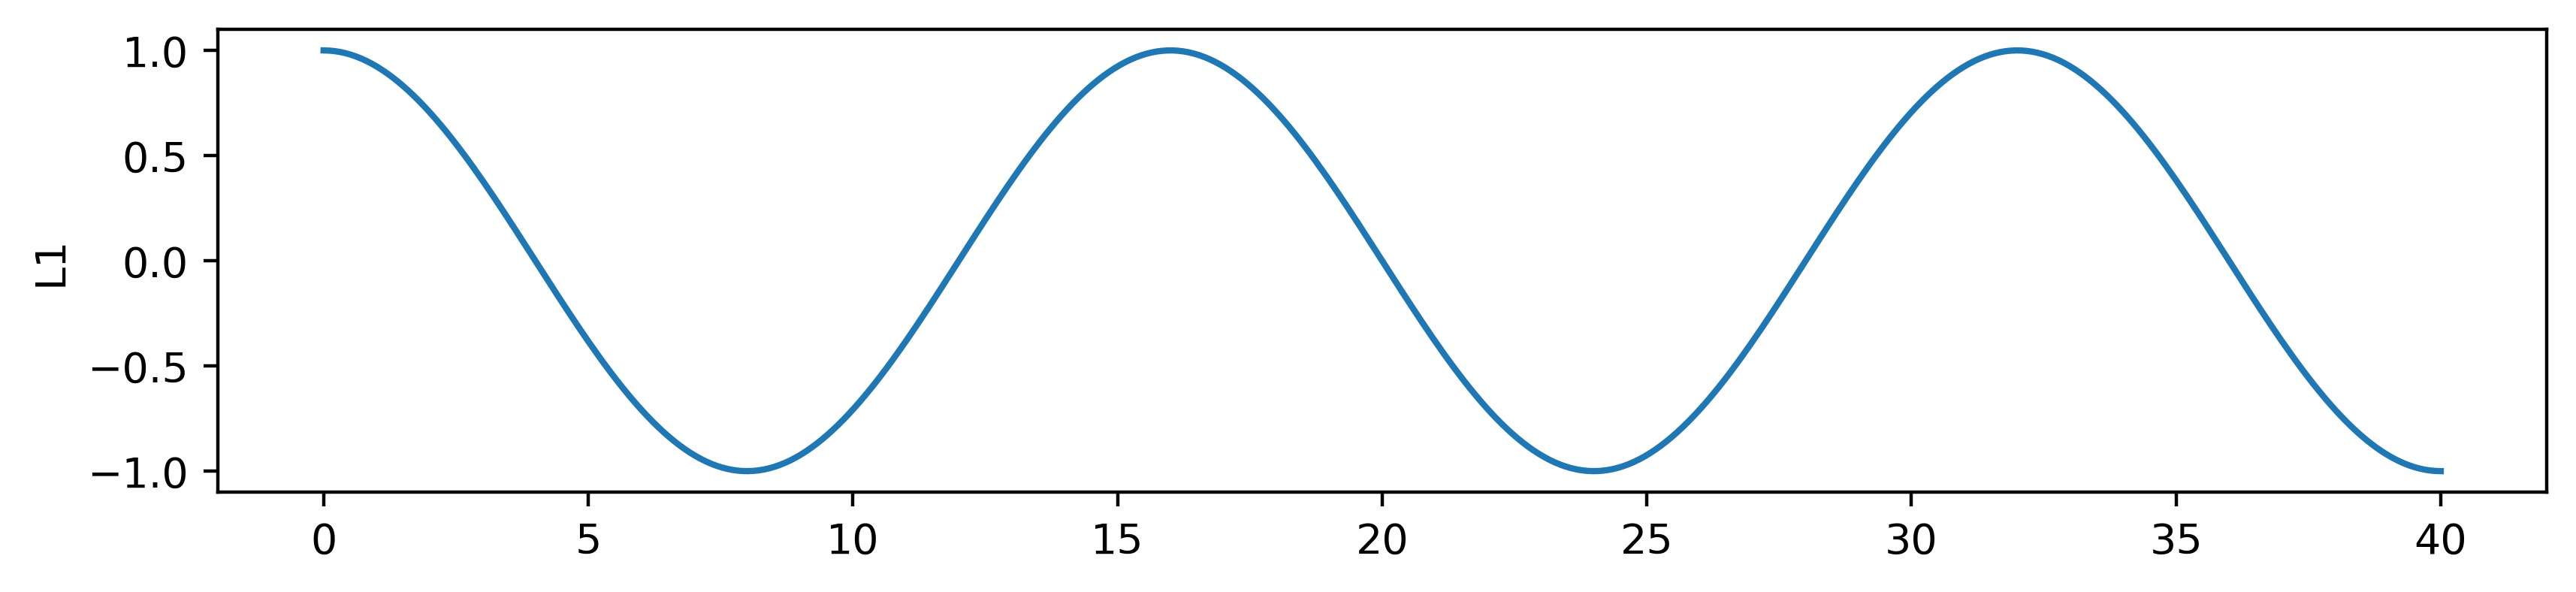

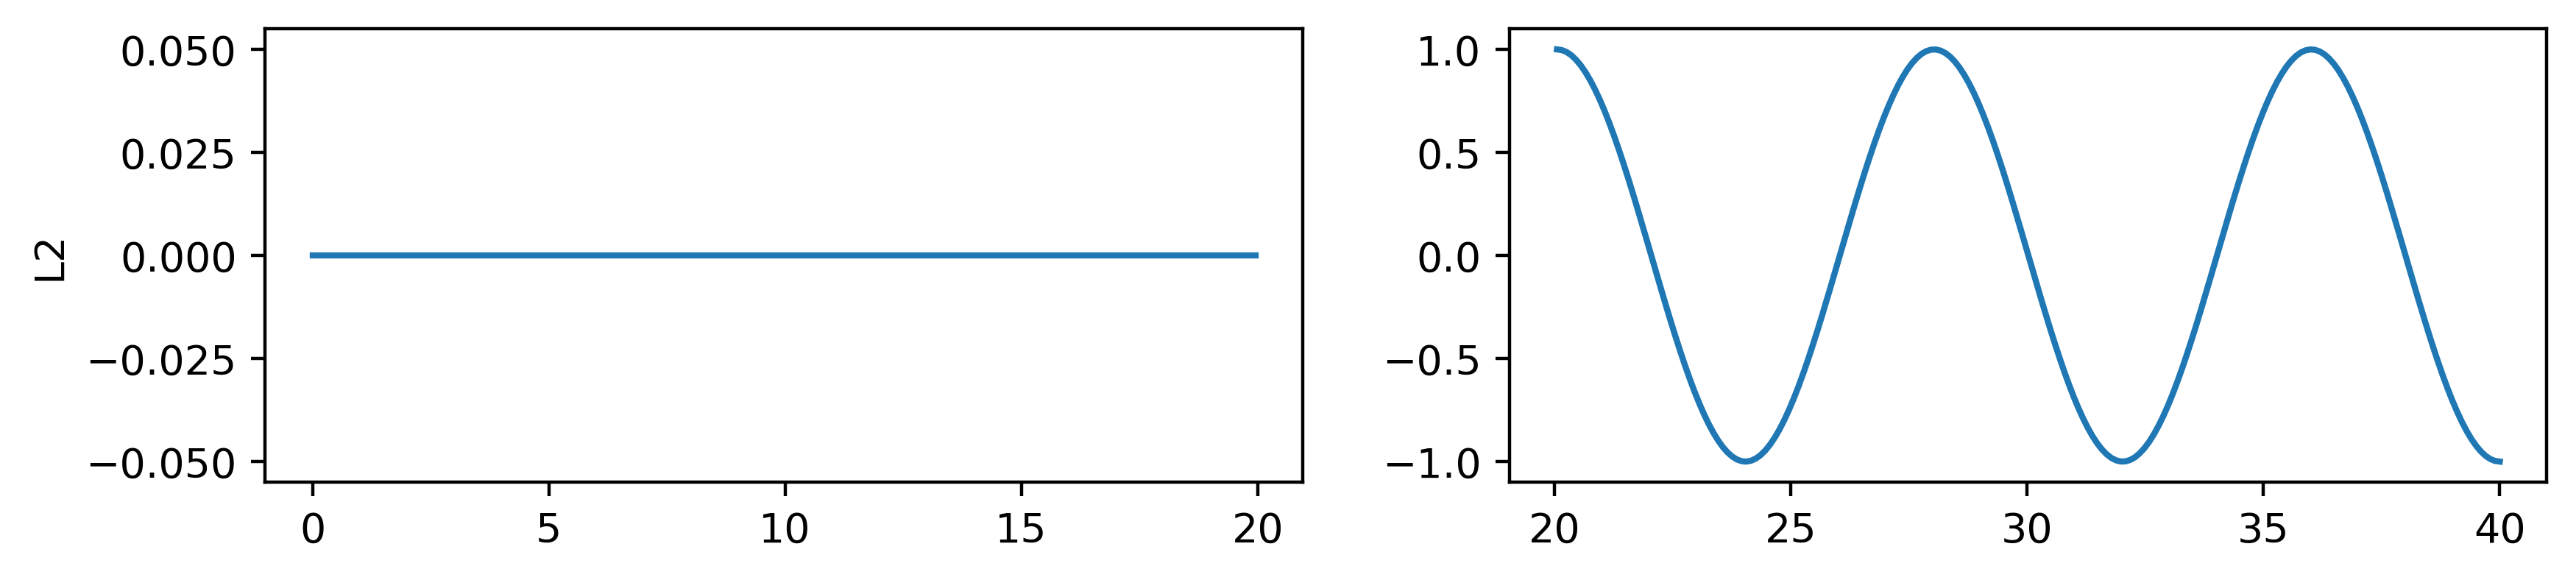

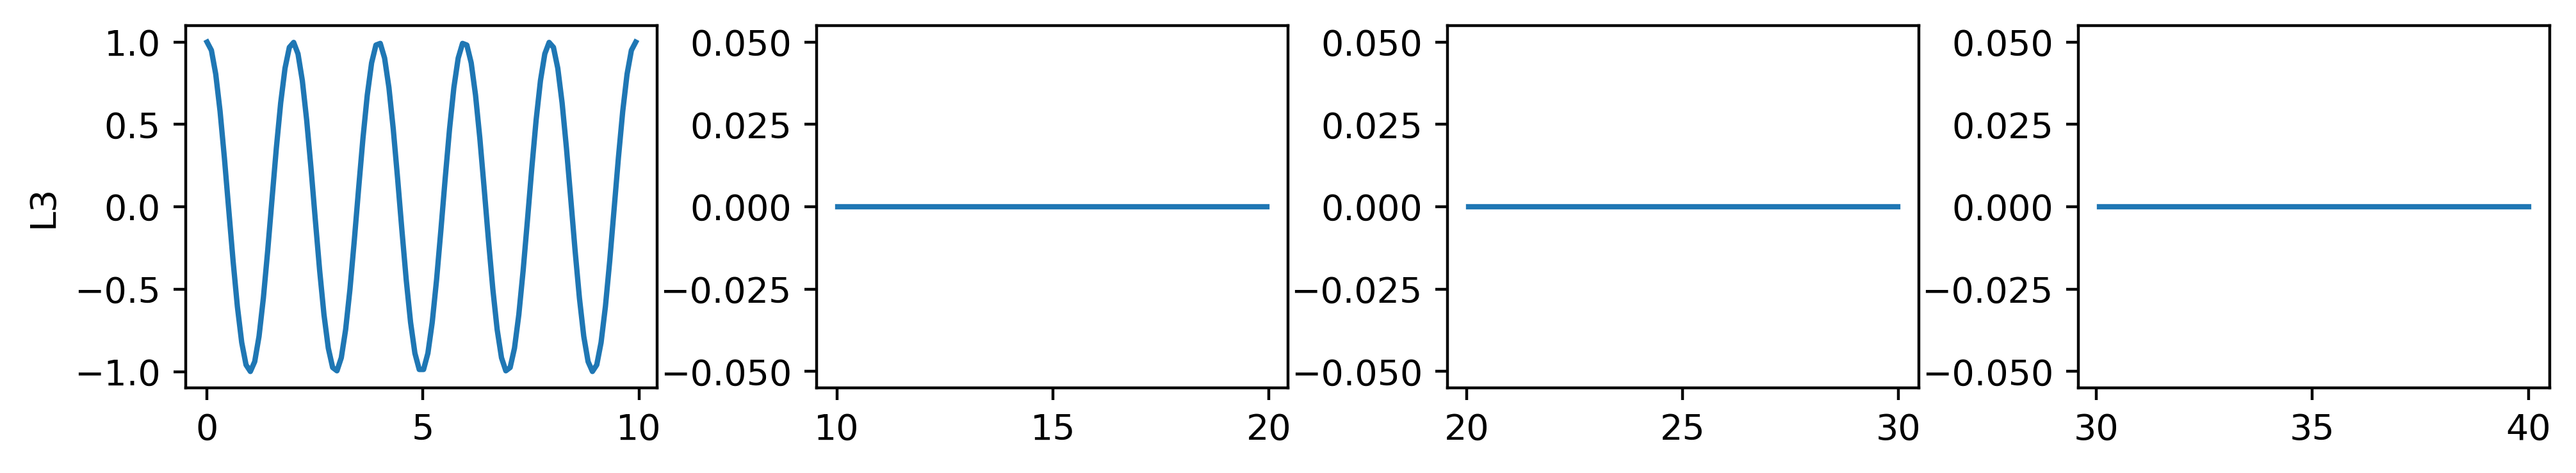

In [20]:
plt.figure(figsize=(10,2))
plt.plot(tspan,mode3)
plt.ylabel("L1")
fig,ax = plt.subplots(1,2)
fig.set_figheight(2)
fig.set_figwidth(10)
ax[0].plot(tspan[:200],mode2[:200])
ax[0].set_ylabel("L2")
ax[1].plot(tspan[200:],mode2[200:])
fig,ax = plt.subplots(1,4)
fig.set_figheight(2)
fig.set_figwidth(10)
fig.tight_layout()
ax[0].plot(tspan[:100],mode1[:100])
ax[0].set_ylabel("L3")
ax[1].plot(tspan[100:200],mode1[100:200])
ax[2].plot(tspan[200:300],mode1[200:300])
ax[3].plot(tspan[300:400],mode1[300:400])

These sum together to form the following temporal pattern.

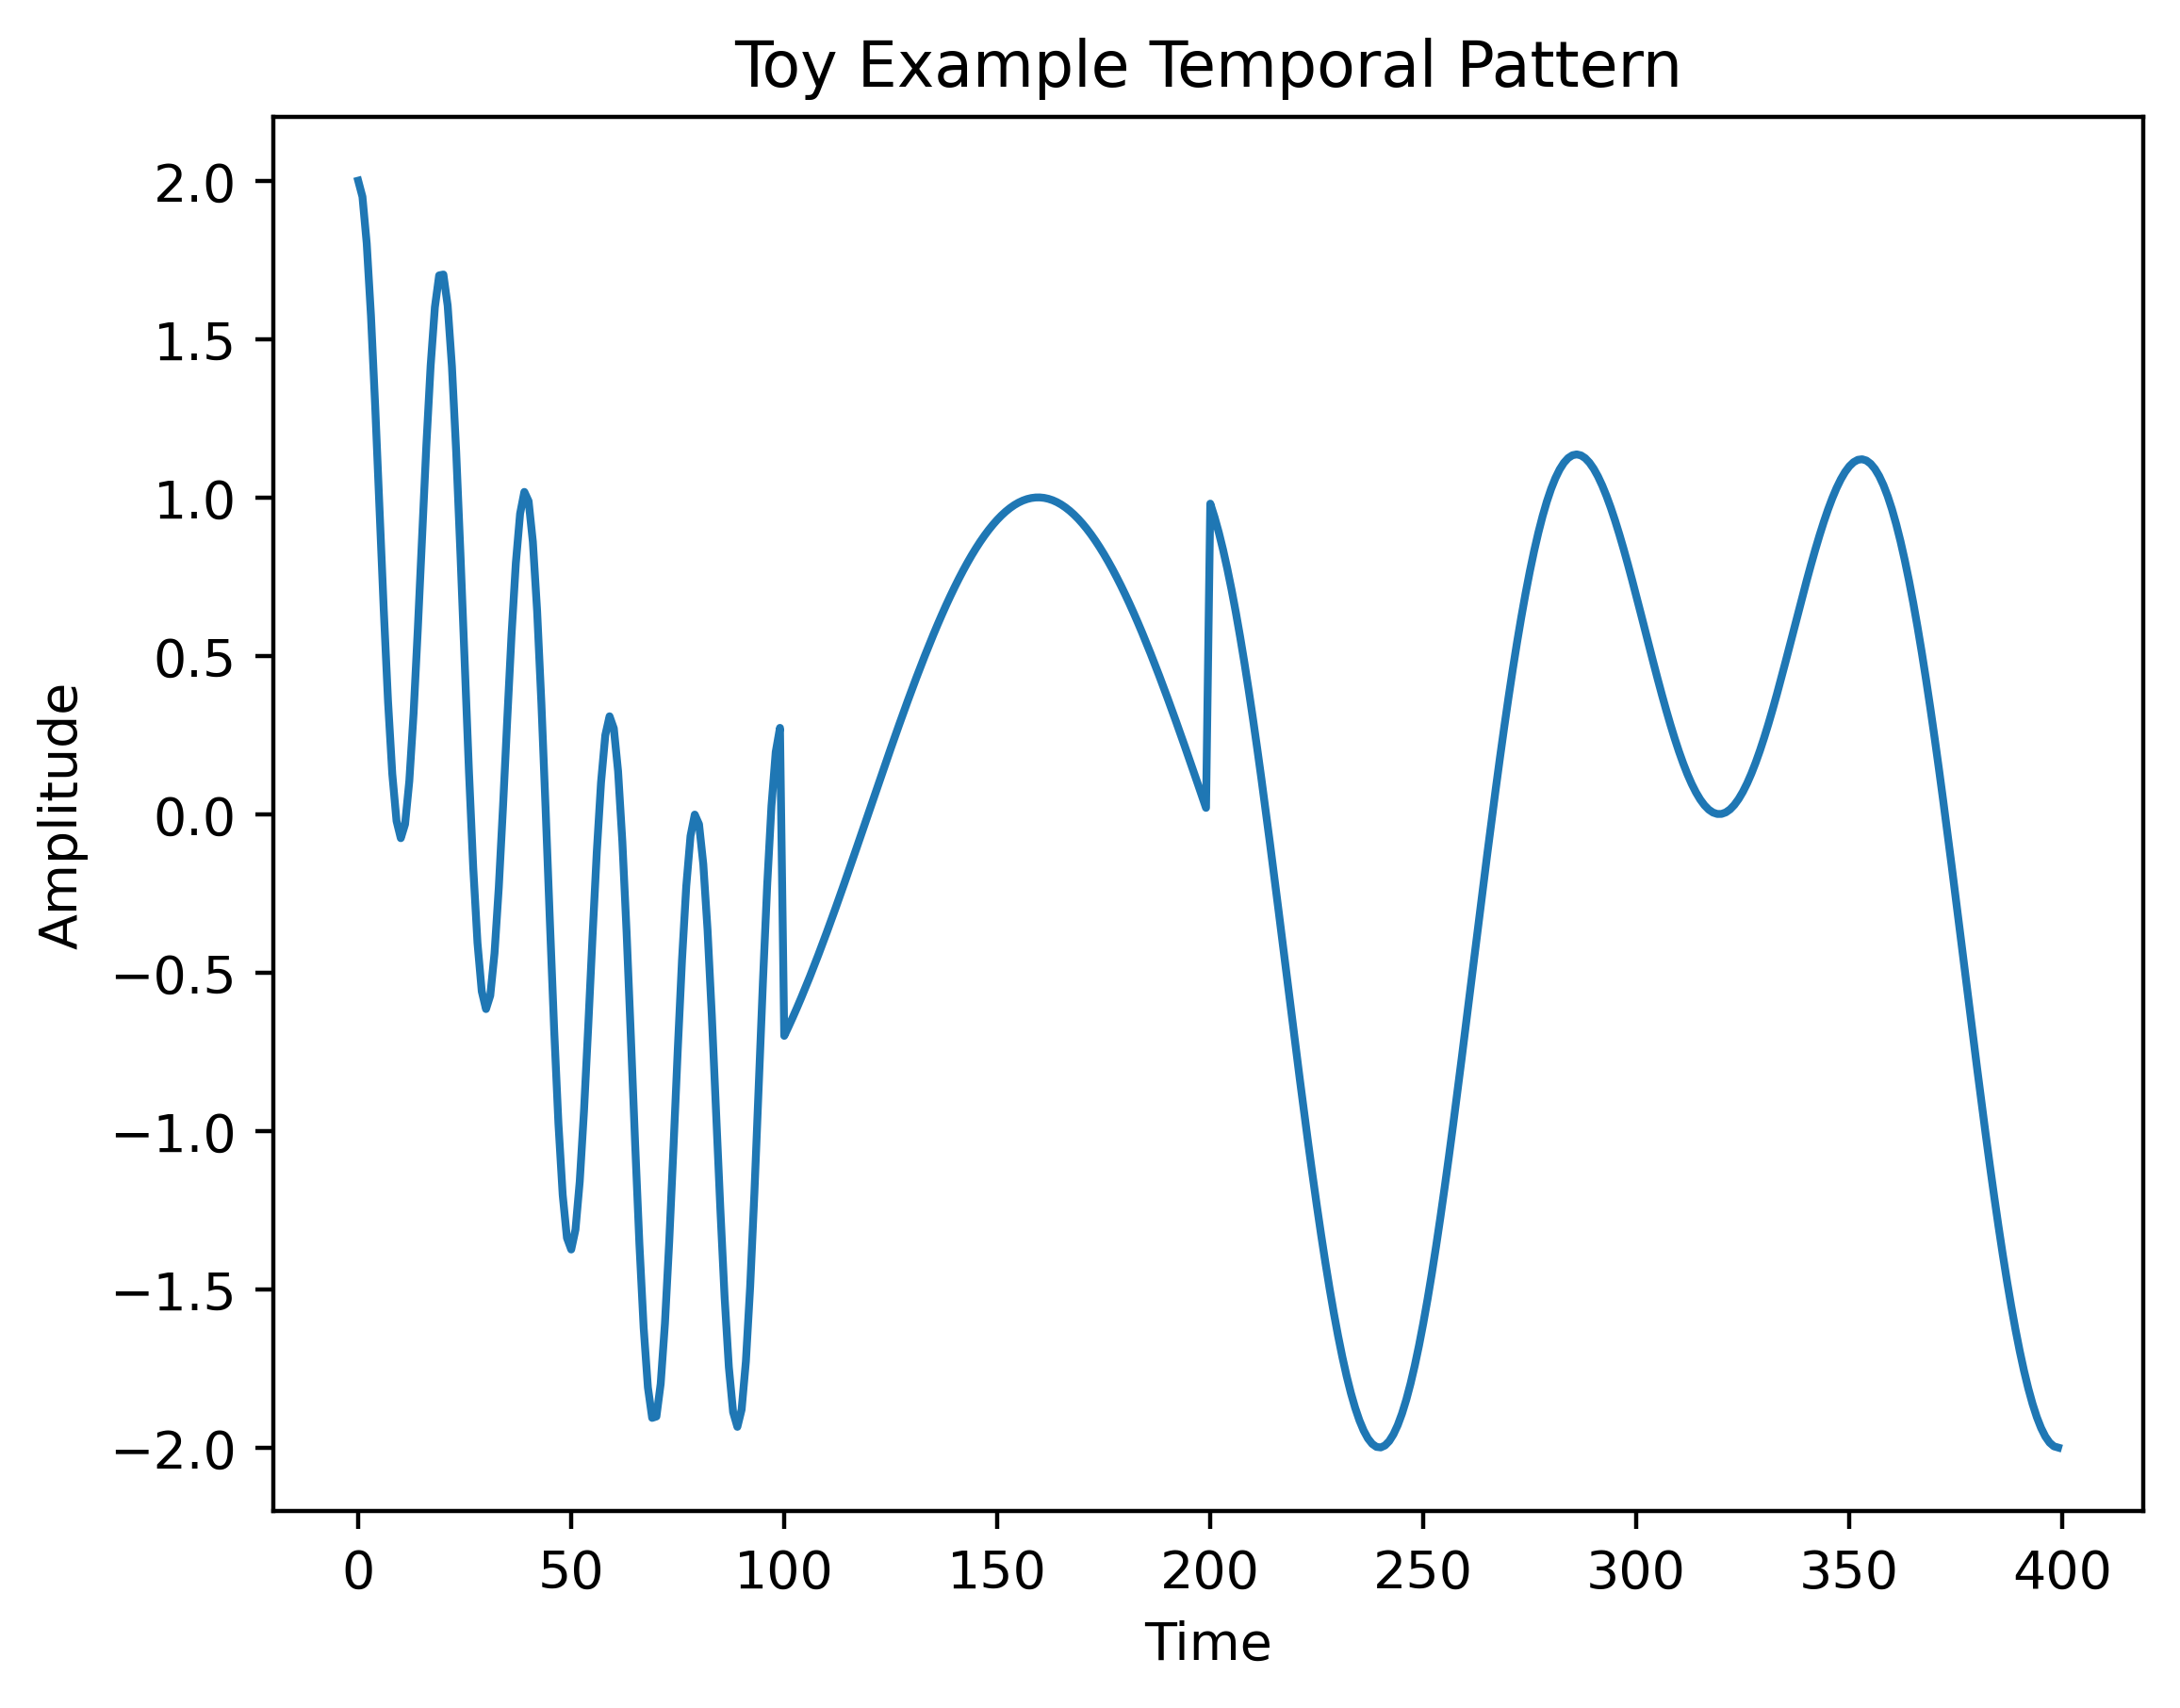

In [21]:
plt.plot(mode1+mode2+mode3)
plt.xlabel("Time")
plt.ylabel("Amplitude")
plt.title("Toy Example Temporal Pattern");

Our single spatial mode is a simple cosine.

Text(0.5, 1.0, 'Toy Example Spatial Pattern')

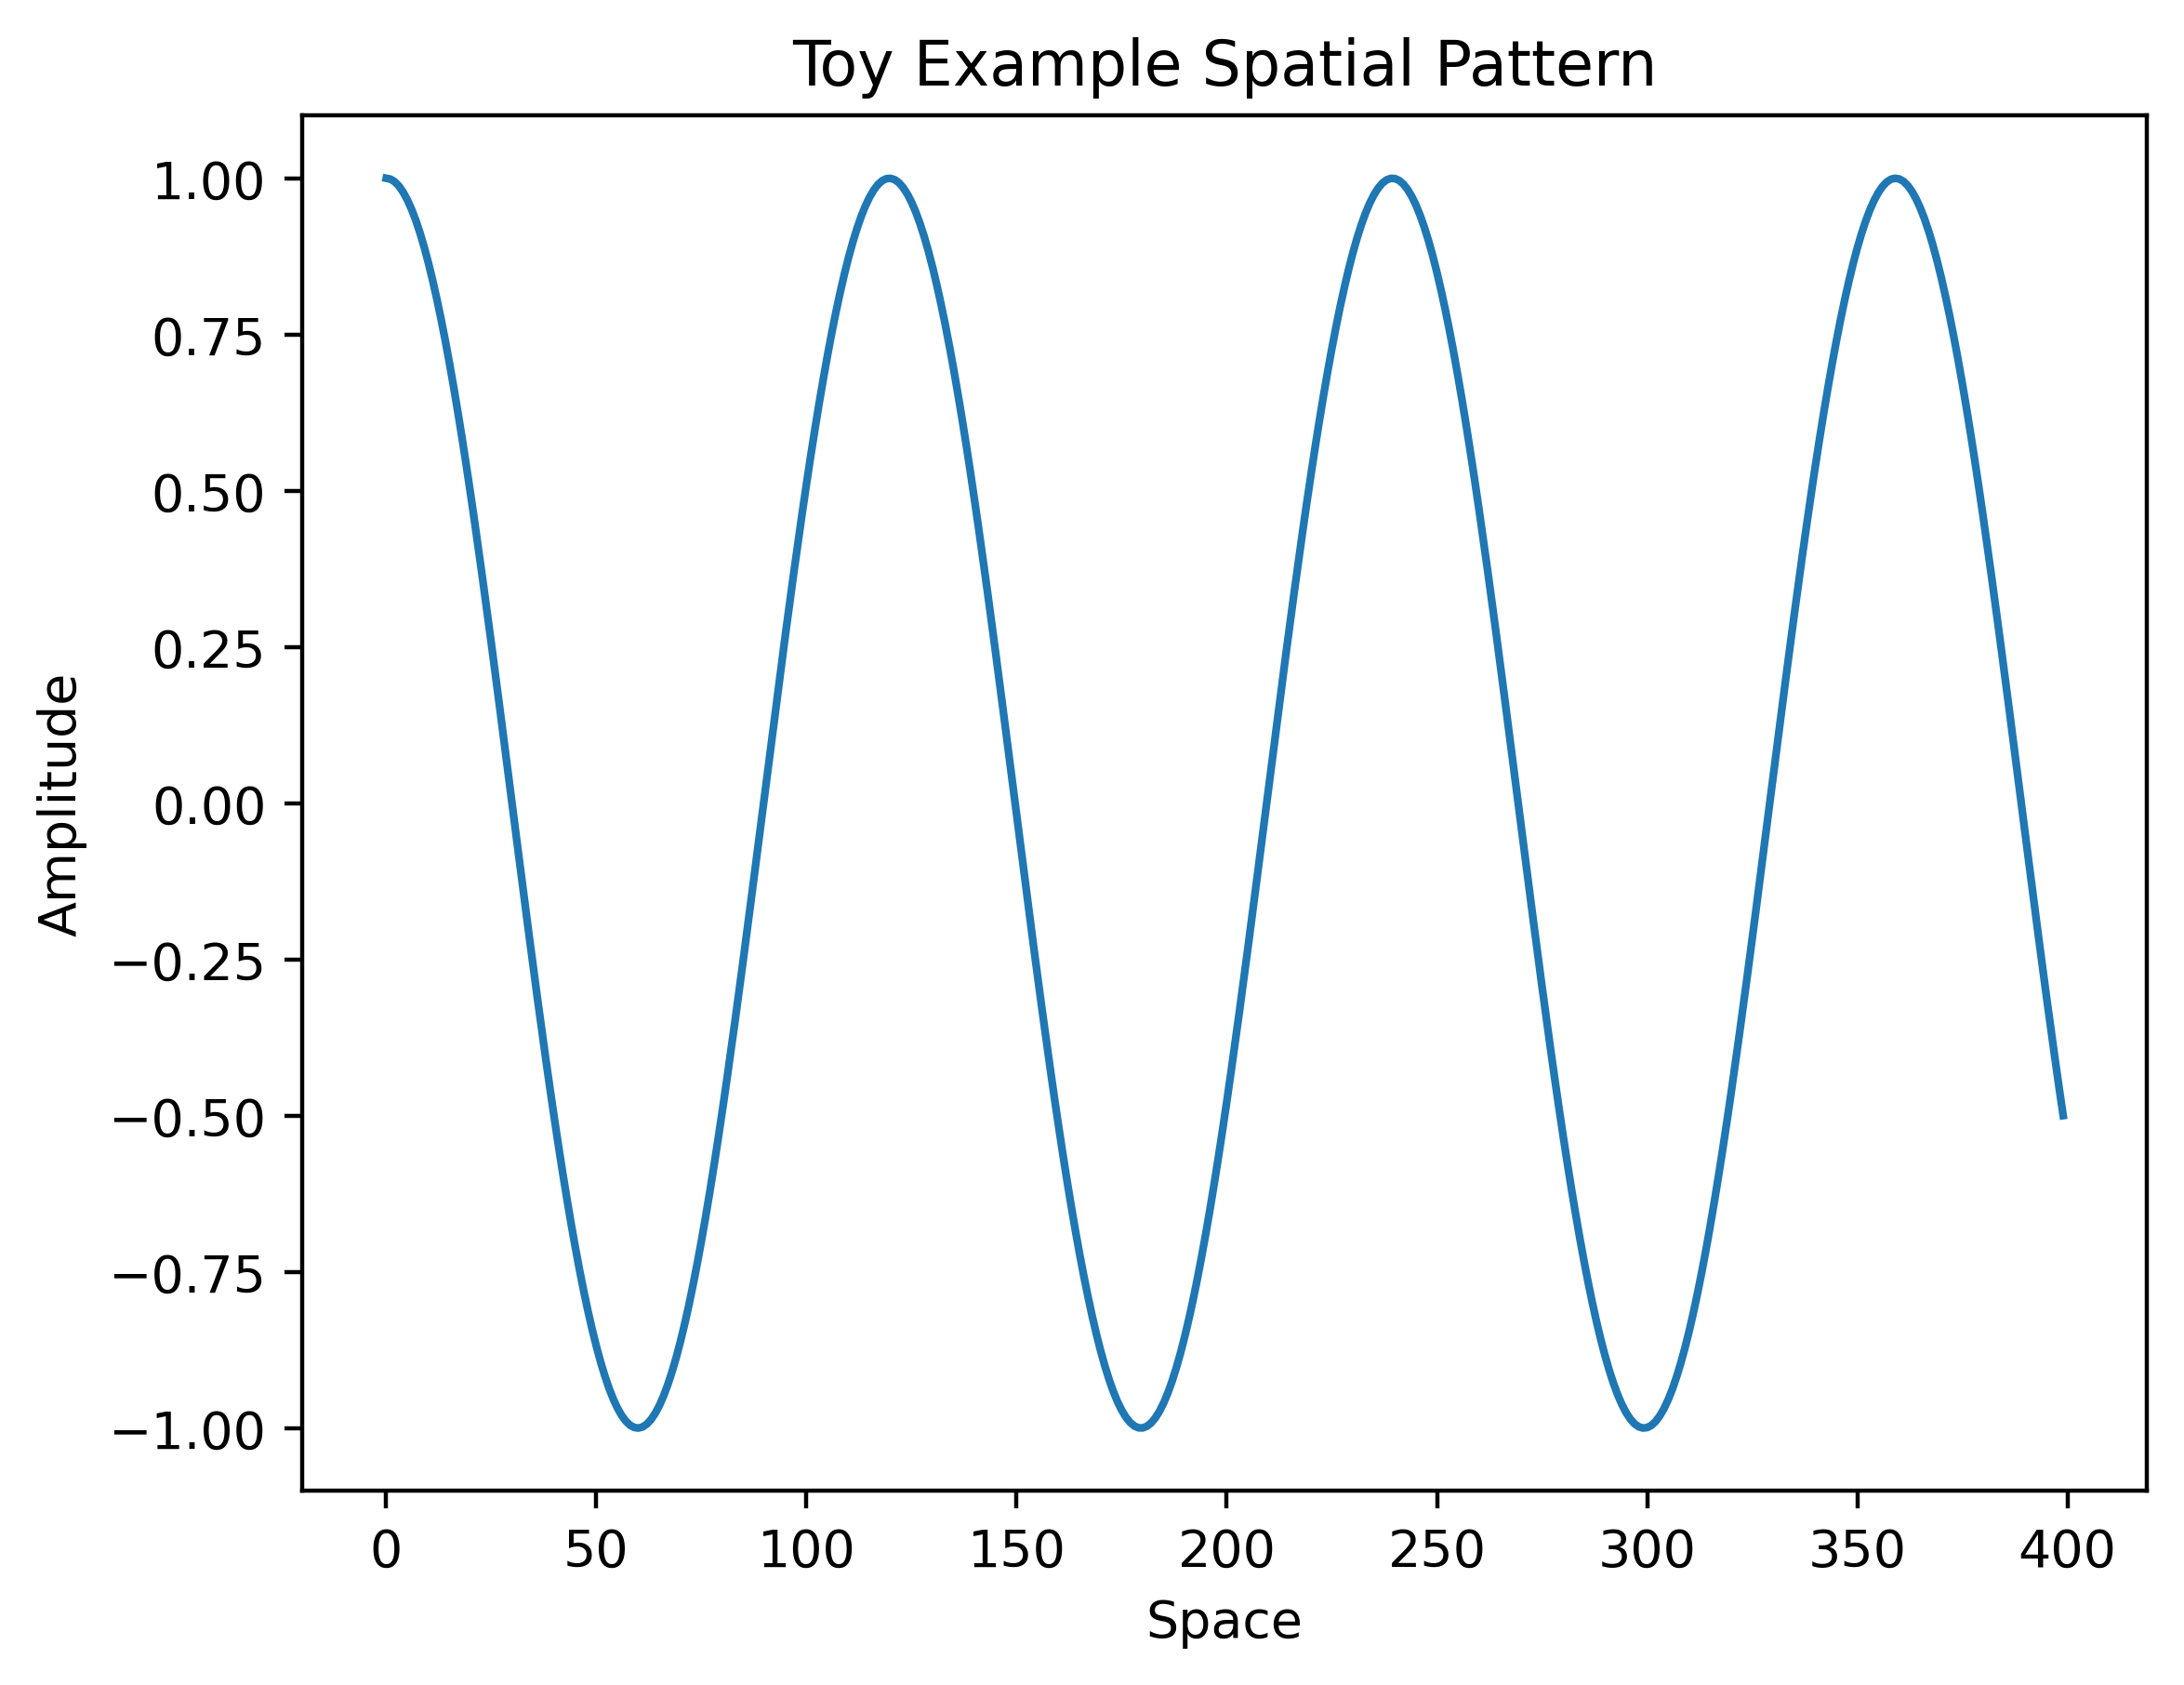

In [22]:
plt.plot(spat_mode)
plt.xlabel("Space")
plt.ylabel("Amplitude")
plt.title("Toy Example Spatial Pattern")

This is what the toy data looks like.

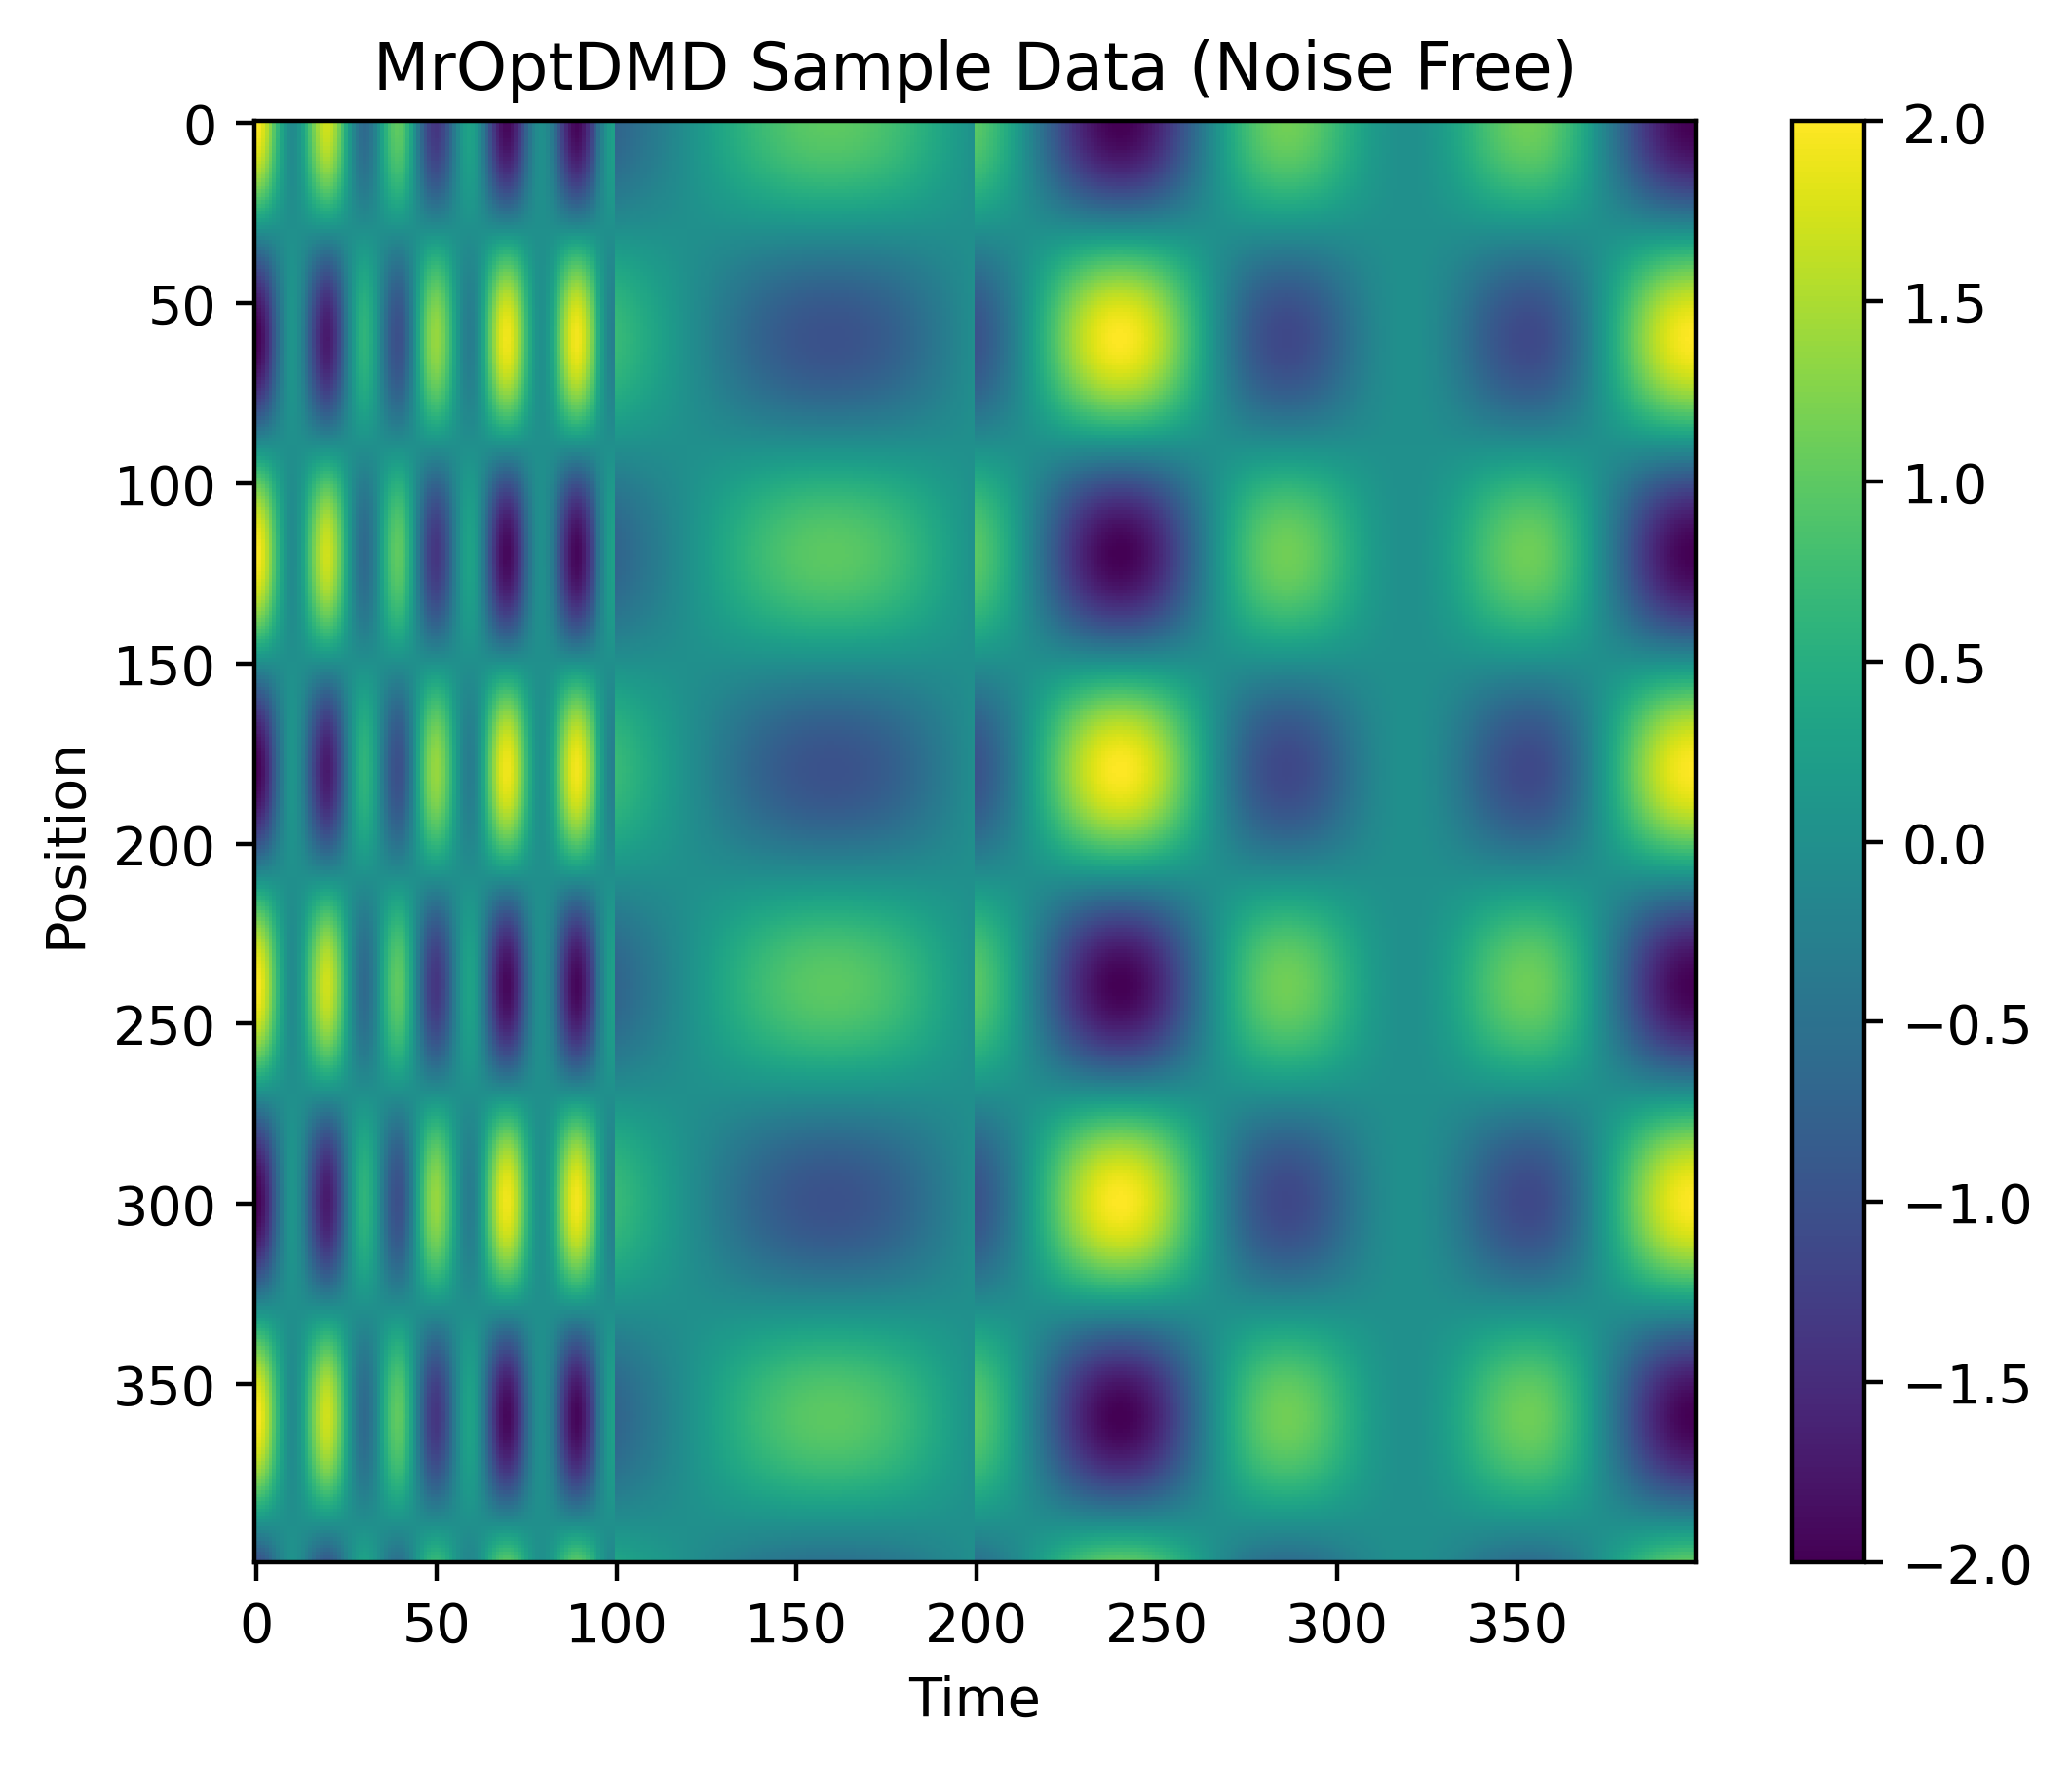

In [23]:
plt.imshow(test_data_noise_free)
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("MrOptDMD Sample Data (Noise Free)")
plt.colorbar()

Next we add Gaussian noise to the data, so that our data looks like this.

In [ ]:
plt.imshow(test_data)
plt.xlabel("Time")
plt.ylabel("Position")
plt.title("MrOptDMD Sample Data (Noisy)")
plt.colorbar()

Now the question becomes how to set up MrOptDMD to fit this data well. In this case we can just look at the data and see that three levels are necessary. However, assuming we don't know how many modes are present in each level, we have to use hyperparameter search methods. Additionally, I have added regularization parameters to OptDMD (which are necessary to fit extremely singular data such as this), so that increases the number of parameters we need to search over.

We will do a random search over the parameter space to find the optimal parameters. We will look for the set of parameters that minimizes an objective function involving the reconstruction RSE and the number of modes used, since we do not want to overfit our data.

*Warning: With some versions of numpy (e.g. numpy 1.24.1), there is a bug either in np.linalg.lstsq or in my regularization code that makes np.linalg.lstsq hang indefinitely. If the progress bar stops moving, try with a different version of numpy. I can confirm it works with numpy 1.23.5.*

In [ ]:
def random_search(data,n):
    search = {'ranks': [],
              'ridges': [],
              'errors': []}
    ranks = []
    ridges = []
    errors = []
    for i in tqdm(range(n)):
        a = np.random.randint(2,7)
        b = np.random.randint(2,7)
        c = np.random.randint(2,7)
        r1 = np.random.uniform(0,3)
        r2 = np.random.uniform(0,3)
        r3 = np.random.uniform(0,3)
        mroptdmd = MrOptDMD([BOPDMD(a,ridge=r1),BOPDMD(b,ridge=r2),BOPDMD(c,ridge=r3)],max_level=2,max_cycles=np.inf)
        mroptdmd.fit(data,np.linspace(0,40,400))
        reconstruct = mroptdmd.reconstructed_data
        search['ranks'].append([a,b,c])
        search['ridges'].append([r1,r2,r3])
        search['errors'].append(RSE(reconstruct,test_data)+0.01*np.linalg.norm([a,b,c]))
    return search

search = random_search(test_data,2000)

  0%|          | 0/2000 [00:00<?, ?it/s]

/home/msw1/.local/lib/python3.11/site-packages/pydmd/snapshots.py:72: UserWarning: Input data condition number 340155.7571943335. Consider preprocessing data, passing in augmented data
matrix, or regularization methods.
  warnings.warn(


Next we can look at the ranks of each level as found by the random search, and the ridge regression penalties.

In [ ]:
n = np.argmin(search['errors'])
ranks = search['ranks'][n]
print("Ranks found by random search: " + str(ranks))
ridges = search['ridges'][n]
print("Ridge regression penalties found by random search: " + str(search['ridges'][n]))
print("Minimum loss achieved: " + str(search['errors'][n]))

So the random search found the correct rank for every level except the first level. This is acceptable since we will easily be able to filter out the additional mode down the line.

Now let's fit MrOptDMD with these parameters and look at the reconstruction.

In [ ]:
mroptdmd = MrOptDMD([BOPDMD(4,ridge=ridges[0]),BOPDMD(ranks[1],ridge=ridges[1]),BOPDMD(ranks[2],ridge=ridges[2])],max_level=2,max_cycles=np.inf)
mroptdmd.fit(test_data,np.linspace(0,40,400))

plt.imshow(np.real(mroptdmd.reconstructed_data))
plt.colorbar();

This is a fairly good reconstruction. The scale is not perfect, but given that the data was noisy I think that's to be expected.

Next let's look at the reconstructions by level.

In [ ]:
fig,ax = plt.subplots(3,1,sharex=True,sharey=True)
for i in range(3):
    img = ax[i].imshow(np.real(mroptdmd.partial_reconstructed_data(i)))
    plt.colorbar(img, ax=ax[i])

Each of these looks correct, minus some noise found at later times on the third level. Let's separate the temporal and spatial components to recover our original data. We'll filter out noise by plotting only modes with amplitudes above some threshold and frequencies above some threshold. These thresholds can be set per level, though in this case the same threshold works for every level.

In [ ]:
fig,ax = plt.subplots(3,2,sharex=True)
fig.tight_layout()
min_freqs = [0.1,0.1,0.1]
min_amps = [1,1,1]
for i in range(3):
    idxs = np.nonzero((np.imag(mroptdmd.partial_eigs(i))>min_freqs[i])*(mroptdmd.partial_amplitudes(i)>min_amps[i]))[0]
    for j in range(idxs.shape[0]):
        ax[i,0].plot(np.linspace(0,40,400),np.real(mroptdmd.partial_dynamics(i)[idxs[j]]))
        ax[i,0].set_yticks([])
        #ax[i,0].set_ylim(-10,10)
        ax[i,1].plot(np.linspace(0,40,400),np.real(mroptdmd.partial_modes(i)[:,idxs[j]]))
        ax[i,1].set_yticks([])
ax[0,0].set_title("Temporal Modes")
ax[0,1].set_title("Spatial Modes")
ax[0,0].set_ylabel("L1")
ax[1,0].set_ylabel("L2")
ax[2,0].set_ylabel("L3")

These are precisely the modes we started with, up to maybe a slight change in phase. This demonstrates that MrOptDMD can extract the true modes from noisy data when given the right hyperparameters, which can be found by something like a random or grid search.